# Практичне завдання 4
## Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень

**Датасет:** Annealing (відпал сталі), OpenML `anneal`, версія з 898 спостережень. **Індивідуальний варіант:** номер у списку групи N = 20, тому `SEED = 42 + 20 = 62`. Це число задає всю випадковість у роботі: розбиття даних, крос-валідацію, моделі та підбір гіперпараметрів Optuna.

**Мета:** порівняти три алгоритми: **Decision Tree** (дерево рішень), **Random Forest** (випадковий ліс) та **XGBoost** (градієнтний бустинг), і з'ясувати:
- як спосіб обробки пропусків (з індикаторами чи без) впливає на якість;
- як чесно підібрати гіперпараметри (**Optuna** + вкладена крос-валідація), щоб оцінка не була завищеною;
- чи є різниця між моделями **статистично значущою**, а не просто випадковою;
- чому моделі інколи не погоджуються між собою (**permutation importance**, **SHAP**).

**План:**
1. Первинний аналіз даних (структура, пропуски, цільова змінна, механізм пропусків)
2. Розбиття та пайплайни обробки (варіанти A і B)
3. Базові моделі та крос-валідація
4. Підбір гіперпараметрів (Optuna) і вкладена крос-валідація
5. Статистичне порівняння (скоригований t-тест Надо–Бенжіо)
6. Фінальна оцінка на тестових даних
7. Важливість ознак (MDI та permutation importance)
8. Аналіз розбіжностей між моделями (SHAP)
9. Висновок і відповіді на контрольні питання

## Підготовка: імпорт бібліотек та фіксація SEED

Тут підключаємо всі потрібні бібліотеки і задаємо головну константу `SEED = 62`. Вона потрібна, щоб при кожному запуску результати були **однаковими** (інакше розбиття, дерева й підбір параметрів щоразу різні).

Коротко про бібліотеки: `pandas/numpy` — таблиці й масиви; `scipy.stats` — статистичні тести (χ², t-розподіл); `scikit-learn` — пайплайни, імпутація, моделі DT/RF, крос-валідація, метрики; `xgboost` — градієнтний бустинг; `optuna` — автоматичний підбір гіперпараметрів; `shap` — пояснення прогнозів. Також друкуємо версії бібліотек (вимога звіту).

In [1]:
import warnings, random, re, sys, time, platform
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import unquote
from scipy import stats
import sklearn, scipy, xgboost, optuna, shap

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, cross_val_score, cross_val_predict)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (f1_score, accuracy_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

N_STUDENT = 20                  # номер у списку групи
SEED = 42 + N_STUDENT           # єдине джерело випадковості: 62
N_TRIALS = 30                   # кількість спроб Optuna в одному підборі
np.random.seed(SEED); random.seed(SEED)
sns.set_style('whitegrid'); plt.rcParams['figure.dpi'] = 100
optuna.logging.set_verbosity(optuna.logging.WARNING)

print('SEED =', SEED)
print('Python', platform.python_version())
for lib in (np, pd, scipy, sklearn, xgboost, optuna, shap):
    print(f'{lib.__name__:12s} {lib.__version__}')

SEED = 62
Python 3.13.16
numpy        2.2.6
pandas       2.3.3
scipy        1.16.2
sklearn      1.8.0
xgboost      3.4.1
optuna       5.0.0
shap         0.53.0


**Опис результату.** Тут лише версії: Python 3.13, numpy 2.2.6, pandas 2.3.3, scipy 1.16.2, scikit-learn 1.8.0, xgboost 3.4.1, optuna 5.0.0, shap 0.53.0. `SEED = 62` (бо номер у списку 20). Саме з цими версіями отримано всі числа нижче; з іншими версіями в четвертому знаці можуть бути дрібні відмінності.

## Етап 1. Первинний аналіз даних

### 1.1 Завантаження датасету та типи ознак

Дані лежать у файлі формату **ARFF** (це текстовий формат Weka: спочатку опис стовпців `@attribute`, потім самі рядки після `@data`). Щоб не залежати від інтернету й додаткових пакетів, ми читаємо файл простою власною функцією:
- беремо назви й типи стовпців із рядків `@attribute` (назви типу `bw%2Fme` розкодовуємо в `bw/me`);
- символ `?` у даних означає **пропуск**, тому замінюємо його на `NaN`;
- числові стовпці (`real`) переводимо в `float`, а всі категоріальні лишаємо типом `object` (за вимогою завдання).

Потім відділяємо цільову змінну `class` від матриці ознак `X`.

In [2]:
ARFF_PATH = 'phpFsFYVN.arff'   # файл має лежати в одній папці з ноутбуком

def load_arff(path):
    names, kinds, rows, in_data = [], [], [], False
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('%'):          # порожні рядки та коментарі
                continue
            low = line.lower()
            if low.startswith('@attribute'):
                m = re.match(r"@attribute\s+'?([^'\s]+)'?\s+(.*)", line, re.I)
                names.append(unquote(m.group(1)))
                kinds.append('num' if m.group(2).strip().lower() in ('real', 'numeric', 'integer') else 'nom')
            elif low.startswith('@data'):
                in_data = True
            elif in_data:
                rows.append([v.strip() for v in line.split(',')])
    df = pd.DataFrame(rows, columns=names).replace('?', np.nan)   # '?' = пропуск
    for c, k in zip(names, kinds):
        if k == 'num':
            df[c] = df[c].astype(float)
    df.attrs['numeric'] = [c for c, k in zip(names, kinds) if k == 'num']   # які стовпці числові за описом ARFF
    return df

raw = load_arff(ARFF_PATH)
y_raw = raw['class']                       # цільова змінна (рядкові мітки класів)
X = raw.drop(columns='class').copy()       # матриця ознак
num_cols_decl = [c for c in raw.attrs['numeric'] if c in X.columns]
cat_cols = [c for c in X.columns if c not in num_cols_decl]
for c in cat_cols:                         # категоріальні -> object із np.nan
    X[c] = X[c].astype(object).where(X[c].notna(), np.nan)

print('Спостережень:', X.shape[0], '| ознак:', X.shape[1])
print('Числових ознак:', len(num_cols_decl), '| категоріальних (object):', len(cat_cols))
print('Версія датасету: OpenML anneal (898 спостережень), 38 ознак + клас')
display(X.dtypes.astype(str).value_counts().rename('кількість').to_frame())
display(raw.head(3))

Спостережень: 898 | ознак: 38
Числових ознак: 6 | категоріальних (object): 32
Версія датасету: OpenML anneal (898 спостережень), 38 ознак + клас


,кількість
object,32
float64,6


,family,product-type,steel,carbon,hardness,temper_rolling,condition,formability,strength,non-ageing,...,s,p,shape,thick,width,len,oil,bore,packing,class
0,NaN,C,A,8.0,0.0,NaN,S,NaN,0.0,NaN,...,NaN,NaN,COIL,0.7,610.0,0.0,NaN,0,NaN,3
1,NaN,C,R,0.0,0.0,NaN,S,2,0.0,NaN,...,NaN,NaN,COIL,3.2,610.0,0.0,NaN,0,NaN,3
2,NaN,C,R,0.0,0.0,NaN,S,2,0.0,NaN,...,NaN,NaN,SHEET,0.7,1300.0,762.0,NaN,0,NaN,3


**Опис результату.** У файлі **898 спостережень** і **38 ознак**: 6 числових (`carbon`, `hardness`, `strength`, `thick`, `width`, `len`) і 32 категоріальні (тип `object`). У прикладі рядків (таблиця) видно багато `NaN`. Це не помилка збору даних: за документацією датасету значення «–» означає **«не застосовно»** (наприклад, для цього виду сталі певна властивість просто не вимірюється), тому значна частина пропусків є **структурною**. Це важливо для всієї роботи: сам факт пропуску може нести інформацію.

### 1.2 Частка пропусків і видалення порожніх та константних ознак

Рахуємо для кожної ознаки, яка частка значень відсутня (`isna().mean()`), і малюємо стовпчикову діаграму (**графік 2**). Потім шукаємо ознаки, які:
- **повністю порожні** (усі значення — пропуск), або
- **константні** (усі значення однакові, `nunique(dropna=False) == 1`).

Така ознака не несе жодної інформації для відрізнення класів, тому її видаляємо.

,marvi,s,p,corr,jurofm,m,bc,exptl,blue/bright/varn/clean,phos,...,steel,product-type,hardness,carbon,strength,shape,width,thick,len,bore
частка пропусків,1.0,1.0,1.0,1.0,1.0,1.0,0.999,0.998,0.993,0.992,...,0.096,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


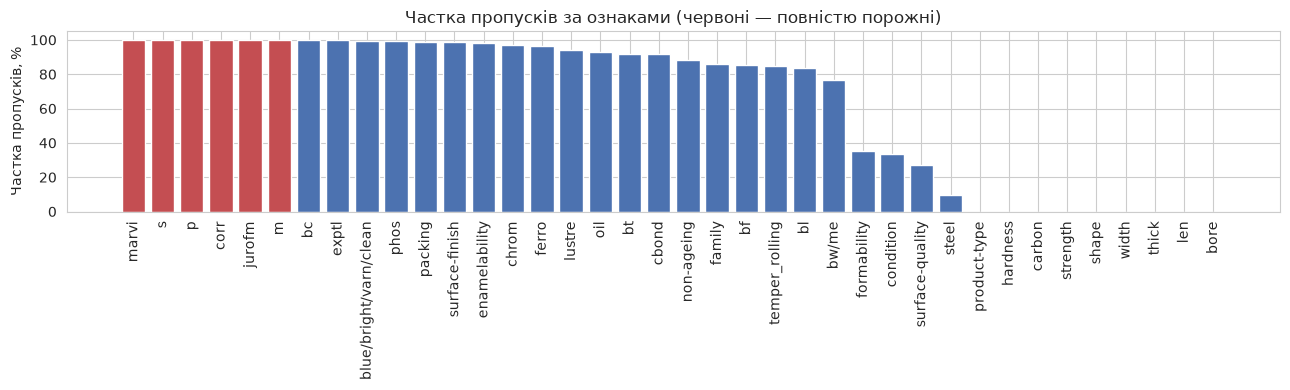

Повністю порожні: ['m', 'marvi', 'corr', 'jurofm', 's', 'p']
Константні (без пропусків): ['product-type'] ['C']
Після видалення: (898, 31)


In [3]:
miss_share = X.isna().mean().sort_values(ascending=False)
display(miss_share.round(3).rename('частка пропусків').to_frame().T)

fig, ax = plt.subplots(figsize=(13, 4))
colors = ['#C44E52' if v >= 0.999 else '#4C72B0' for v in miss_share.values]
ax.bar(range(len(miss_share)), miss_share.values * 100, color=colors)
ax.set_xticks(range(len(miss_share))); ax.set_xticklabels(miss_share.index, rotation=90)
ax.set_ylabel('Частка пропусків, %'); ax.set_title('Частка пропусків за ознаками (червоні — повністю порожні)')
plt.tight_layout(); plt.show()

empty = [c for c in X.columns if X[c].isna().all()]
const = [c for c in X.columns if c not in empty and X[c].nunique(dropna=False) == 1]
print('Повністю порожні:', empty)
print('Константні (без пропусків):', const, [X[c].iloc[0] for c in const])
X = X.drop(columns=empty + const)
print('Після видалення:', X.shape)

**Опис результату.** Графік 2 показує, що ознаки діляться на три групи:
- **6 ознак повністю порожні** (100%, червоні стовпчики): `marvi`, `s`, `p`, `corr`, `jurofm`, `m`;
- **ще 19 ознак мають 76–99.9% пропусків** (наприклад, `bc` має лише одне непорожнє значення з 898, `exptl` — два);
- **ознаки з помірною часткою пропусків:** `formability` (≈35%), `condition` (≈34%), `surface-quality` (≈27%), `steel` (≈10%); а 9 ознак (`hardness`, `carbon`, `strength`, `shape`, `width`, `thick`, `len`, `bore`, `product-type`) пропусків не мають.

Видалили **7 ознак**: 6 повністю порожніх (вони не несуть жодної інформації) і `product-type` (константа `'C'`, бо ознака, що ніколи не змінюється, не може допомогти розрізнити класи). Лишилось **31 ознака** (6 числових + 25 категоріальних). Майже порожні ознаки (`bc`, `exptl`) **залишаємо**: вони не повністю порожні, а їхні індикатори пропусків можуть бути корисними.

### 1.3 Цільова змінна та рідкісні класи

Дивимось, скільки об'єктів у кожному класі (**графік 1**). У цьому датасеті клас **3 домінує**, а клас **1** має лише кілька об'єктів; клас **4**, описаний у документації, у даних **відсутній**. Для рідкісних класів треба ухвалити рішення: залишити, об'єднати чи виключити. Нижче в таблиці показано, скільки об'єктів цього класу лишиться на кожному рівні перевірки (у train, в одному блоці крос-валідації, у внутрішньому блоці Optuna), бо саме мала кількість може зламати крос-валідацію.

,кількість,"частка, %"
class,,
1,8,0.89
2,99,11.02
3,684,76.17
5,67,7.46
U,40,4.45


Класи, що є в даних: ['1', '2', '3', '5', 'U'] | клас 4 у даних відсутній


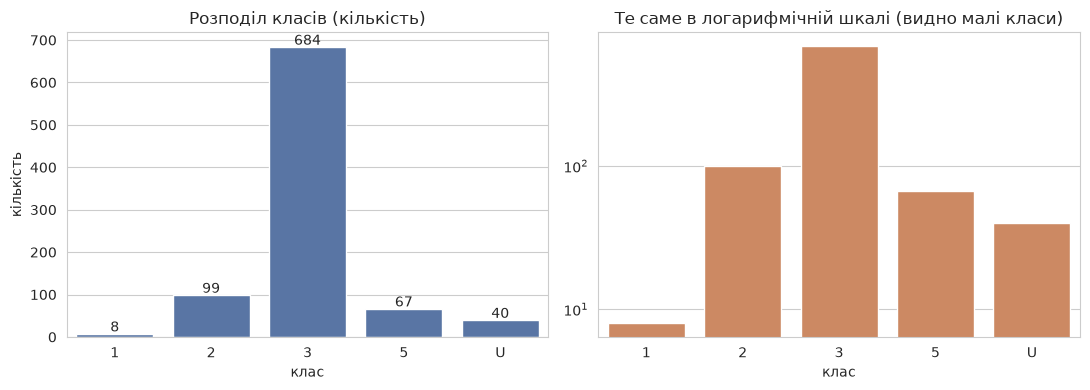

In [4]:
counts = y_raw.value_counts().sort_index()
share = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({'кількість': counts, 'частка, %': share}))
print('Класи, що є в даних:', list(counts.index), '| клас 4 у даних відсутній')

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=counts.index, y=counts.values, ax=ax[0], color='#4C72B0')
for i, v in enumerate(counts.values): ax[0].text(i, v + 5, str(v), ha='center')
ax[0].set_title('Розподіл класів (кількість)'); ax[0].set_xlabel('клас'); ax[0].set_ylabel('кількість')
sns.barplot(x=counts.index, y=counts.values, ax=ax[1], color='#DD8452')
ax[1].set_yscale('log'); ax[1].set_title('Те саме в логарифмічній шкалі (видно малі класи)')
ax[1].set_xlabel('клас')
plt.tight_layout(); plt.show()

**Опис результату.** Клас **3** у даних домінує: 684 об'єкти (76.2%). Далі: клас 2 — 99 (11.0%), клас 5 — 67 (7.5%), клас U — 40 (4.5%) і клас **1 — лише 8 об'єктів (0.9%)**. Класу 4 у даних немає (тому лишається 5 класів). Праворуч той самий розподіл у логарифмічній шкалі, де малі класи видно краще.

**Рішення щодо рідкісних класів: залишаємо всі п'ять класів без змін.** Об'єднувати клас 1 з іншим не можна, бо це окремий справжній тип сталі, і штучне злиття змінило б саму задачу; виключати його теж не варто, бо ми б приховали найскладніший випадок. Наслідок для крос-валідації видно у таблиці наступної секції: у train клас 1 матиме 6 об'єктів, тож у кожному блоці 5-блочної CV на перевірку потрапляє лише 1–2 таких об'єкти, а у внутрішній 3-блочній CV Optuna у тренувальній частині лишається 2–3. Цього ще вистачає, щоб кожен клас був присутній у кожному тренувальному блоці (інакше XGBoost видав би помилку), але **оцінки macro F1 будуть дуже шумними**: один помилково класифікований об'єкт класу 1 різко змінює середнє F1 по класах.

### 1.4 Аналіз механізму пропусків (MCAR / MAR / MNAR)

**Ідея.** Якщо пропуски виникають зовсім випадково (**MCAR**), то факт «значення відсутнє» не повинен залежати від класу. Якщо ж залежить, то пропуск сам несе інформацію про клас (**MAR/MNAR**), і його варто передати моделі (це ідея варіанта B з індикаторами).

**Що робимо.** Для кожної ознаки з пропусками будуємо таблицю спряженості «пропуск / не пропуск × клас» (розмір 2×5) і перевіряємо **незалежність** тестом **χ²** (хі-квадрат).
- Оскільки багато клітинок мають дуже малі очікувані частоти (менше 5), класичний χ² ненадійний. Тому додатково рахуємо **p-значення методом Монте-Карло (перестановочний тест)**: 5000 разів випадково перемішуємо мітки класів і дивимось, як часто випадковий χ² не менший за реальний. Це аналог точного критерію Фішера для таблиць більше ніж 2×2.
- Перевіряємо кілька десятків ознак одразу, тому додаємо **поправку Холма** на множинні перевірки (інакше частина «значущих» результатів з'явилась би випадково).
- **Cramér's V** (від 0 до 1) показує силу зв'язку між пропуском і класом: чим більше, тим сильніше пропуск «знає» клас.

У завданні згадано 35 ознак; у нас після очищення всього 31, тому тестуємо всі, де є пропуски.

,ознака,пропусків,частка,chi2,p (chi2),клітинок <5,p (Монте-Карло),Cramer's V,p (Холм),зв'язок з класом
0,surface-quality,244,0.2717,495.5804,0.0000,0.1,0.0002,0.7429,0.0046,ТАК
1,family,772,0.8597,463.7476,0.0000,0.1,0.0002,0.7186,0.0046,ТАК
2,ferro,868,0.9666,384.9498,0.0000,0.4,0.0002,0.6547,0.0046,ТАК
3,chrom,872,0.9710,332.0928,0.0000,0.4,0.0002,0.6081,0.0046,ТАК
4,non-ageing,793,0.8831,260.1410,0.0000,0.2,0.0002,0.5382,0.0046,ТАК
5,temper_rolling,761,0.8474,227.1319,0.0000,0.1,0.0002,0.5029,0.0046,ТАК
6,exptl,896,0.9978,222.9967,0.0000,0.5,0.0002,0.4983,0.0046,ТАК
7,condition,303,0.3374,151.0473,0.0000,0.1,0.0002,0.4101,0.0046,ТАК
8,formability,318,0.3541,136.1624,0.0000,0.1,0.0002,0.3894,0.0046,ТАК
9,phos,891,0.9922,87.5030,0.0000,0.4,0.0004,0.3122,0.0046,ТАК


Ознак з пропусками: 23; значущий зв'язок із класом (Холм, α=0.05): 20
Медіанна частка клітинок із очікуваною частотою <5: 0.2


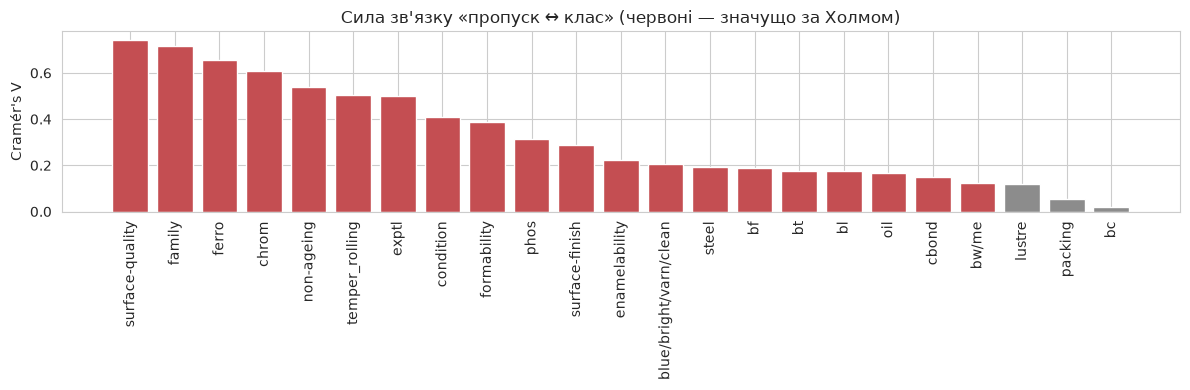


Таблиця спряженості для ознаки з найсильнішим зв'язком: surface-quality


class,1,2,3,5,U
surface-quality,,,,,
пропуск,8,89,80,67,0
є значення,0,10,604,0,40


In [5]:
from scipy.stats import chi2_contingency

y_idx = pd.Series(y_raw).astype('category').cat.codes.values      # класи як 0..4 (для тесту)
K = y_idx.max() + 1
class_tot = np.bincount(y_idx, minlength=K)
N_all = len(y_idx)
rng = np.random.RandomState(SEED)
B = 5000

def chi2_from_rows(miss_row, class_tot, N):
    # miss_row: скільки пропусків у кожному класі; другий рядок — решта
    tab = np.vstack([class_tot - miss_row, miss_row]).astype(float)
    exp = tab.sum(1, keepdims=True) * tab.sum(0, keepdims=True) / N
    return ((tab - exp) ** 2 / exp).sum()

rows = []
for f in X.columns:
    m = X[f].isna().values
    if m.sum() == 0:
        continue
    miss_row = np.bincount(y_idx[m], minlength=K)
    tab = np.vstack([class_tot - miss_row, miss_row])
    chi2, p_chi2, dof, exp = chi2_contingency(tab, correction=False)
    small = (exp < 5).mean()                                       # частка клітинок із малими очікуваними частотами
    obs = chi2_from_rows(miss_row, class_tot, N_all)
    cnt = 0
    for _ in range(B):
        perm = rng.permutation(y_idx)
        cnt += chi2_from_rows(np.bincount(perm[m], minlength=K), class_tot, N_all) >= obs - 1e-9
    p_mc = (cnt + 1) / (B + 1)
    rows.append({'ознака': f, 'пропусків': int(m.sum()), 'частка': m.mean(), 'chi2': chi2,
                 'p (chi2)': p_chi2, 'клітинок <5': small, 'p (Монте-Карло)': p_mc,
                 "Cramer's V": np.sqrt(chi2 / N_all)})
mech = pd.DataFrame(rows)

# поправка Холма на множинні перевірки (за p Монте-Карло)
order = mech['p (Монте-Карло)'].argsort().values
mm = len(mech); adj = np.empty(mm); run = 0
for rank, i in enumerate(order):
    run = max(run, (mm - rank) * mech['p (Монте-Карло)'].iloc[i]); adj[i] = min(1.0, run)
mech['p (Холм)'] = adj
mech['зв\'язок з класом'] = np.where(mech['p (Холм)'] < 0.05, 'ТАК', 'ні')
mech = mech.sort_values("Cramer's V", ascending=False).reset_index(drop=True)
display(mech.round(4))

print(f"Ознак з пропусками: {len(mech)}; значущий зв'язок із класом (Холм, α=0.05): {(mech['p (Холм)'] < 0.05).sum()}")
print('Медіанна частка клітинок із очікуваною частотою <5:', mech['клітинок <5'].median().round(2))

fig, ax = plt.subplots(figsize=(12, 4))
col = ['#C44E52' if s == 'ТАК' else '#8C8C8C' for s in mech['зв\'язок з класом']]
ax.bar(mech['ознака'], mech["Cramer's V"], color=col)
ax.set_xticklabels(mech['ознака'], rotation=90); ax.set_ylabel("Cramér's V")
ax.set_title("Сила зв'язку «пропуск ↔ клас» (червоні — значущо за Холмом)")
plt.tight_layout(); plt.show()

top_f = mech.loc[0, 'ознака']
print(f"\nТаблиця спряженості для ознаки з найсильнішим зв'язком: {top_f}")
display(pd.crosstab(X[top_f].isna().map({True: 'пропуск', False: 'є значення'}), y_raw))

**Опис результату.** З 31 ознаки **пропуски є у 23**. Тест перевіряє, чи залежить факт пропуску від класу (чим менше p і більше Cramér's V, тим сильніший зв'язок).
- Після поправки Холма **20 із 23 ознак мають значущий зв'язок пропуску з класом** (p<0.05). Незначущі лише `lustre` (p за Холмом ≈ 0.07), `packing` (≈ 0.89) і `bc` (≈ 1.0, бо в `bc` лише одне непорожнє значення).
- Сила зв'язку подекуди дуже велика: Cramér's V = **0.74** для `surface-quality`, **0.72** для `family`, 0.65 для `ferro`, 0.61 для `chrom`, 0.54 для `non-ageing`.
- Для більшості ознак ≈20% клітинок таблиці мають очікувану частоту менше 5, тому ми довіряємо p-значенню Монте-Карло, яке не вимагає великих частот (у цілому воно збігається з висновком класичного χ²).

**Приклад (таблиця спряженості для `surface-quality`):** значення пропущене в усіх 8 об'єктів класу 1, у 89 із 99 класу 2 і в усіх 67 класу 5, але лише у 80 із 684 класу 3 і **в жодному** з 40 об'єктів класу U. Тобто пропуск прямо вказує на клас.

**Висновок: пропуски НЕ схожі на MCAR.** Вони пов'язані з класом, тобто це **MAR або MNAR** (механізм, що залежить від спостережуваних даних або від самого «неіснуючого» значення). Чітко відрізнити MAR від MNAR лише за даними неможливо. До того ж більшість пропусків тут «структурні» («не застосовно»), тож **індикатори пропусків (варіант B) мають бути корисними**: очікуємо, що варіант B дасть кращу якість, ніж варіант A.

### 1.5 Кодування цільової змінної

XGBoost приймає лише числові мітки класів `0, 1, …, K−1`. `LabelEncoder` перетворює рядкові мітки (`'1','2','3','5','U'`) на числа. Оскільки класу 4 немає, отримаємо **5 класів**, і числа підряд без пропусків (інакше XGBoost видав би помилку).

In [6]:
le = LabelEncoder()
y_enc = le.fit_transform(y_raw)
print('Відповідність:', dict(zip(le.classes_, le.transform(le.classes_))))
print('Кількість класів K =', len(le.classes_))

Відповідність: {'1': np.int64(0), '2': np.int64(1), '3': np.int64(2), '5': np.int64(3), 'U': np.int64(4)}
Кількість класів K = 5


**Опис результату.** Мітки стали числами: `'1' → 0`, `'2' → 1`, `'3' → 2`, `'5' → 3`, `'U' → 4`. Класів **5**, і числа йдуть підряд (клас 4 відсутній, тому «дірки» немає, і XGBoost працюватиме без помилок).

## Етап 2. Розбиття даних і пайплайни обробки

### 2.1 Стратифікований розбиття train / test

Ділимо дані **80% / 20%** зі `stratify=y_enc` (щоб у train і test були однакові частки кожного класу, особливо рідкісних) та `random_state=SEED`. **Тестова вибірка використовується лише один раз**, наприкінці, для фінальної оцінки. Увесь підбір гіперпараметрів і крос-валідація робляться тільки на train.

Після розбиття перевіряємо, скільки об'єктів кожного класу лишилось на різних рівнях. Це важливо для рідкісних класів: якщо клас має менше об'єктів, ніж блоків у крос-валідації, будуть попередження або помилки.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.2, stratify=y_enc, random_state=SEED)
print('Train:', X_train.shape, '| Test:', X_test.shape)

tr_c, te_c = np.bincount(y_train), np.bincount(y_test)
chk = pd.DataFrame({'клас': le.classes_, 'усього': np.bincount(y_enc), 'train': tr_c, 'test': te_c,
                    'у train-частині зовн. блоку (≈4/5)': np.floor(tr_c * 0.8).astype(int),
                    'у внутр. train Optuna (≈2/3 від того)': np.floor(np.floor(tr_c * 0.8) * 2 / 3).astype(int)})
display(chk.set_index('клас'))
print('Мінімум об\'єктів класу в train =', tr_c.min(), '(5 блоків CV → у кожному блоці валідації 1–2 об\'єкти цього класу)')
print('Мінімум об\'єктів класу в test  =', te_c.min())

Train: (718, 31) | Test: (180, 31)


,усього,train,test,у train-частині зовн. блоку (≈4/5),у внутр. train Optuna (≈2/3 від того)
клас,,,,,
1,8,6,2,4,2
2,99,79,20,63,42
3,684,547,137,437,291
5,67,54,13,43,28
U,40,32,8,25,16


Мінімум об'єктів класу в train = 6 (5 блоків CV → у кожному блоці валідації 1–2 об'єкти цього класу)
Мінімум об'єктів класу в test  = 2


**Опис результату.** Train містить **718** об'єктів, test — **180**. У test потрапило по 2, 20, 137, 13 і 8 об'єктів класів 1, 2, 3, 5 і U (частки як у всьому датасеті завдяки `stratify`). Клас 1 має **6 об'єктів у train і лише 2 у test**. Два стовпчики праворуч показують, скільки об'єктів лишається в тренувальній частині зовнішнього блоку (≈4/5) і всередині Optuna (≈2/3 від цього): для класу 1 це ≈4 і ≈2. Тобто на кожному рівні кожен клас ще є, але клас 1 дуже малий.

### 2.2 Два варіанти обробки (A і B) та пайплайни

Пропуски треба чимось заповнити (**імпутація**), бо звичайні моделі sklearn прямо з `NaN` не завжди працюють. Робимо **два варіанти**:
- **Варіант A (базова імпутація):** числові ознаки — заповнюємо **медіаною**; категоріальні — **модою** (найчастішим значенням); потім **one-hot** кодування категорій (кожна категорія стає окремим стовпцем 0/1).
- **Варіант B (з індикаторами):** те саме, **плюс** додаткові бінарні стовпці-індикатори `missingindicator_<ознака>` (1, якщо значення було пропущене). Так модель бачить не лише «заповнене» значення, а й сам факт пропуску.

Найважливіше: усе це кладемо **всередину `Pipeline`**. Тоді при крос-валідації імпутер «вчиться» (рахує медіани й моди) лише на тренувальній частині кожного блоку й не підглядає у валідаційну. Якби ми заповнили пропуски до розбиття на всьому датасеті, виник би **витік даних**.

`make_model` створює одну з трьох моделей: **DT** (одне дерево), **RF** (багато дерев, усереднення), **XGB** (дерева, що будуються послідовно й виправляють помилки попередніх).

In [8]:
def build_preprocessor(with_indicators: bool) -> ColumnTransformer:
    transformers = [
        ('num', SimpleImputer(strategy='median'),
         make_column_selector(dtype_include='number')),
        ('cat', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), make_column_selector(dtype_exclude='number')),
    ]
    if with_indicators:
        transformers.append(
            ('miss', MissingIndicator(features='missing-only'), make_column_selector()))
    return ColumnTransformer(transformers)

def make_model(name, params=None):
    params = params or {}
    if name == 'DT':
        return DecisionTreeClassifier(random_state=SEED, **params)
    if name == 'RF':
        return RandomForestClassifier(random_state=SEED, n_jobs=-1, **params)
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric='mlogloss', **params)

def build_pipeline(name, with_indicators=True, params=None):
    return Pipeline([('prep', build_preprocessor(with_indicators)),
                     ('clf', make_model(name, params))])

MODELS = ['DT', 'RF', 'XGB']
MODEL_FULL = {'DT': 'Decision Tree', 'RF': 'Random Forest', 'XGB': 'XGBoost'}

# Подивимось, що виходить після обробки (fit лише на train)
for v, ind in [('A', False), ('B', True)]:
    prep = build_preprocessor(ind).fit(X_train)
    names = prep.get_feature_names_out()
    n_ind = sum('missingindicator_' in n for n in names)
    print(f'Варіант {v}: {len(names)} ознак після обробки, з них індикаторів пропусків: {n_ind}')
prepB = build_preprocessor(True).fit(X_train)
print('Приклади індикаторів:', [n for n in prepB.get_feature_names_out() if 'missingindicator_' in n][:6])

Варіант A: 54 ознак після обробки, з них індикаторів пропусків: 0
Варіант B: 77 ознак після обробки, з них індикаторів пропусків: 23
Приклади індикаторів: ['miss__missingindicator_family', 'miss__missingindicator_steel', 'miss__missingindicator_temper_rolling', 'miss__missingindicator_condition', 'miss__missingindicator_formability', 'miss__missingindicator_non-ageing']


**Опис результату.** Варіант A дає **54 ознаки** після обробки (6 числових + one-hot категорій). Варіант B дає **77 ознак** = ті самі 54 + **23 індикатори пропусків** (по одному для кожної ознаки, де в train є хоча б один пропуск). Назви мають вигляд `missingindicator_family`, `missingindicator_steel` тощо. Усе це відбувається всередині пайплайну, тож імпутер і кодувальник навчаються лише на тренувальній частині.

## Етап 3. Базові моделі та крос-валідація

Для кожного варіанта (A, B) і кожної з трьох моделей з **типовими** (стандартними) параметрами робимо **повторну стратифіковану крос-валідацію 5×3**: train ділиться на 5 блоків, по черзі 4 блоки навчання і 1 перевірка, і так 3 рази з різним перемішуванням. Разом **15 оцінок** на модель. Це дає не одне число, а **середнє ± стандартне відхилення**, тобто видно, наскільки результат стабільний.

Метрики: `accuracy`, **macro F1** (головна; середнє F1 по класах, де рідкісні класи важать так само, як великі) та `balanced accuracy`.

**Важливо:** усі моделі та варіанти оцінюються на **одному й тому самому об'єкті `cv`** із тими самими 15 розбиттями. Це потрібно для парного статистичного порівняння (Етап 5). Нижче явно перевіряємо, що розбиття збігаються.

In [9]:
scoring = {'acc': 'accuracy', 'f1m': 'f1_macro', 'bacc': 'balanced_accuracy'}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

# перевірка: cv дає ті самі розбиття при кожному виклику
s1 = [te.tolist() for _, te in cv.split(X_train, y_train)]
s2 = [te.tolist() for _, te in cv.split(X_train, y_train)]
print('Розбиття однакові при повторному виклику cv:', s1 == s2, '| кількість оцінок:', len(s1))

base = {}
for variant, ind in [('A', False), ('B', True)]:
    for name in MODELS:
        t0 = time.time()
        base[(variant, name)] = cross_validate(build_pipeline(name, ind), X_train, y_train,
                                               cv=cv, scoring=scoring)
        print(f'варіант {variant} {name}: готово за {time.time() - t0:.1f} с')

def pm(a):   # середнє ± стд
    return f'{np.mean(a):.4f} ± {np.std(a, ddof=1):.4f}'

def base_table(variant):
    return pd.DataFrame({MODEL_FULL[n]: {'Accuracy': pm(base[(variant, n)]['test_acc']),
                                          'Macro F1': pm(base[(variant, n)]['test_f1m']),
                                          'Balanced Acc': pm(base[(variant, n)]['test_bacc'])}
                         for n in MODELS}).T

print('\nТаблиця 1. Крос-валідація 5x3, варіант A (без індикаторів), типові параметри')
display(base_table('A'))
print('Таблиця 2. Крос-валідація 5x3, варіант B (з індикаторами), типові параметри')
display(base_table('B'))

Розбиття однакові при повторному виклику cv: True | кількість оцінок: 15


варіант A DT: готово за 0.4 с


варіант A RF: готово за 4.2 с


варіант A XGB: готово за 2.1 с


варіант B DT: готово за 0.5 с


варіант B RF: готово за 4.1 с


варіант B XGB: готово за 1.7 с

Таблиця 1. Крос-валідація 5x3, варіант A (без індикаторів), типові параметри


,Accuracy,Macro F1,Balanced Acc
Decision Tree,0.9461 ± 0.0175,0.8914 ± 0.0762,0.8993 ± 0.0770
Random Forest,0.9452 ± 0.0195,0.9105 ± 0.0581,0.9125 ± 0.0640
XGBoost,0.9485 ± 0.0174,0.8883 ± 0.0816,0.8853 ± 0.0895


Таблиця 2. Крос-валідація 5x3, варіант B (з індикаторами), типові параметри


,Accuracy,Macro F1,Balanced Acc
Decision Tree,0.9940 ± 0.0044,0.9687 ± 0.0549,0.9689 ± 0.0577
Random Forest,0.9921 ± 0.0064,0.9638 ± 0.0520,0.9572 ± 0.0575
XGBoost,0.9865 ± 0.0056,0.9448 ± 0.0682,0.9388 ± 0.0764


**Опис результату.** Спочатку перевірка: `cv` дає **однакові 15 розбиттів** при повторному виклику (`True`), тож усі моделі й варіанти оцінені на одних і тих самих блоках.

**Таблиця 1 (варіант A, без індикаторів):** macro F1 дорівнює DT 0.891 ± 0.076, RF 0.911 ± 0.058, XGBoost 0.888 ± 0.082; accuracy в усіх близько 0.945–0.949.
**Таблиця 2 (варіант B, з індикаторами):** macro F1 дорівнює DT 0.969 ± 0.055, RF 0.964 ± 0.052, XGBoost 0.945 ± 0.068; accuracy ≈ 0.987–0.994.

Як це читати простими словами:
- **Індикатори пропусків дуже допомагають.** Macro F1 виріс на ≈0.077 (DT), ≈0.053 (RF) і ≈0.057 (XGBoost), а accuracy зросла приблизно з 0.945 до 0.99. Це збігається з аналізом механізму пропусків: пропуск сам «підказує» клас.
- **Accuracy майже не відрізняє моделі** (в усіх ≈0.99, «ефект стелі»), а macro F1 розкриває відмінності, бо враховує рідкісні класи.
- **Стандартні відхилення великі** (0.05–0.08), бо в кожному блоці лише 1–2 об'єкти класу 1. Тому різниці між моделями в межах ≈0.02 можуть бути просто шумом, що ми перевіримо тестом на Етапі 5.

## Етап 4. Підбір гіперпараметрів (Optuna)

**Optuna** — бібліотека, яка автоматично шукає хороші гіперпараметри. Вона пробує кілька десятків комбінацій (`trial`), для кожної рахує оцінку якості та вчиться, які області значень перспективні (алгоритм **TPE**), тому розумніша за повний перебір сітки.

Правила чесності:
1. У цільову функцію передаємо **весь пайплайн** (обробка + модель), щоб імпутер не бачив валідаційні блоки.
2. Підбір робимо лише на тренувальних даних, у внутрішній 3-блочній крос-валідації (3 блоки, бо клас 1 малий; див. таблицю вище).
3. Оптимізуємо `f1_macro`, а семплер Optuna має `seed=SEED`.

Підбір виконуємо для **варіанта B** (з індикаторами). Простір пошуку взято з завдання.

In [10]:
def suggest_params(trial, name):
    if name == 'DT':
        return {
            'max_depth': trial.suggest_int('max_depth', 2, 20),
            'min_samples_split': trial.suggest_int('min_samples_split', 2, 20),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced']),
        }
    if name == 'RF':
        return {
            'n_estimators': trial.suggest_int('n_estimators', 100, 500, step=50),
            'max_depth': trial.suggest_int('max_depth', 3, 30),
            'min_samples_leaf': trial.suggest_int('min_samples_leaf', 1, 10),
            'max_features': trial.suggest_categorical('max_features', ['sqrt', 'log2', 0.5]),
            'class_weight': trial.suggest_categorical('class_weight', [None, 'balanced', 'balanced_subsample']),
        }
    return {  # XGB
        'n_estimators': trial.suggest_int('n_estimators', 50, 400),
        'max_depth': trial.suggest_int('max_depth', 2, 10),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.3, log=True),
        'subsample': trial.suggest_float('subsample', 0.6, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.6, 1.0),
        'min_child_weight': trial.suggest_float('min_child_weight', 1, 10, log=True),
    }

def tune(name, X_tr, y_tr, n_trials=N_TRIALS):
    inner = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    def objective(trial):
        pipe = build_pipeline(name, True, suggest_params(trial, name))   # весь пайплайн!
        return cross_val_score(pipe, X_tr, y_tr, cv=inner, scoring='f1_macro').mean()
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=n_trials)
    return study

print('Функції підбору готові. Кількість спроб на один підбір:', N_TRIALS)

Функції підбору готові. Кількість спроб на один підбір: 30


### 4.1 Підбір на всій тренувальній вибірці (фінальні моделі)

Запускаємо `tune()` один раз для кожної моделі на **всьому train**. Знайдені параметри підуть у фінальні моделі. Також запам'ятовуємо `study.best_value`: це найкраща оцінка, яку Optuna побачила під час пошуку. **Вона оптимістично завищена**, бо ми обрали максимум серед багатьох зашумлених оцінок (докладніше в 4.3).

In [11]:
studies, tune_time = {}, {}
for name in MODELS:
    t0 = time.time()
    studies[name] = tune(name, X_train, y_train)
    tune_time[name] = time.time() - t0
    print(f'{MODEL_FULL[name]}: best_value = {studies[name].best_value:.4f}, час {tune_time[name]:.0f} с')

Decision Tree: best_value = 0.9426, час 3 с


Random Forest: best_value = 0.9627, час 80 с


XGBoost: best_value = 0.9618, час 23 с


**Опис результату.** Optuna зробила по 30 спроб на кожну модель. Найкраща оцінка внутрішньої крос-валідації (`best_value`): **DT — 0.9426** (знайдена на 17-й спробі), **RF — 0.9627** (25-та спроба), **XGBoost — 0.9618** (24-та). Часу пішло приблизно 3 с, 80 с і 23 с відповідно (на іншому комп'ютері буде інакше) (RF найдорожчий, бо будує сотні дерев в кожній спробі). Пам'ятаємо, що `best_value` — це максимум з 30 зашумлених оцінок, тож його не можна вважати якістю моделі.

### 4.2 Таблиця 4 та графіки Optuna

**Таблиця 4** — найкращі гіперпараметри для кожної моделі. Для кожної моделі показуємо два графіки:
- **історія оптимізації** (`plot_optimization_history`): як змінювалась оцінка від спроби до спроби та де знайдено максимум (чи «вийшла» оптимізація на плато);
- **важливість гіперпараметрів** (`plot_param_importances`): які параметри найсильніше впливали на оцінку.

In [12]:
rows = []
for name in MODELS:
    for k, v in studies[name].best_params.items():
        rows.append({'Модель': MODEL_FULL[name], 'Параметр': k, 'Значення': round(v, 4) if isinstance(v, float) else v})
print('Таблиця 4. Найкращі гіперпараметри (Optuna, варіант B)')
display(pd.DataFrame(rows))
display(pd.DataFrame({MODEL_FULL[n]: {'best_value (macro F1)': round(studies[n].best_value, 4),
                                       'номер найкращої спроби': studies[n].best_trial.number,
                                       'спроб': len(studies[n].trials)} for n in MODELS}).T)

Таблиця 4. Найкращі гіперпараметри (Optuna, варіант B)


,Модель,Параметр,Значення
0,Decision Tree,max_depth,16
1,Decision Tree,min_samples_split,3
2,Decision Tree,min_samples_leaf,1
3,Decision Tree,class_weight,None
4,Random Forest,n_estimators,200
5,Random Forest,max_depth,29
6,Random Forest,min_samples_leaf,1
7,Random Forest,max_features,sqrt
8,Random Forest,class_weight,None
9,XGBoost,n_estimators,335


,best_value (macro F1),номер найкращої спроби,спроб
Decision Tree,0.9426,17.0,30.0
Random Forest,0.9627,25.0,30.0
XGBoost,0.9618,24.0,30.0


**Опис результату (Таблиця 4).** Найкращі параметри:
- **DT:** `max_depth=16`, `min_samples_split=3`, `min_samples_leaf=1`, без ваг класів. Тобто дерево майже нічим не обмежене: рідкісному класу треба дозволити окремі маленькі листки.
- **RF:** 200 дерев, глибина 29, `min_samples_leaf=1`, `max_features='sqrt'`, без ваг. Теж глибокі дерева з дрібними листками.
- **XGBoost:** 335 дерев, але **дуже неглибокі (`max_depth=3`) і повільне навчання (`learning_rate≈0.016`)**, `subsample≈0.94`, `colsample_bytree≈0.66`. Це «обережніше» налаштування, ніж стандартне (дерева глибини 6 і швидкість 0.3), яке менше схильне до перенавчання на малих класах.

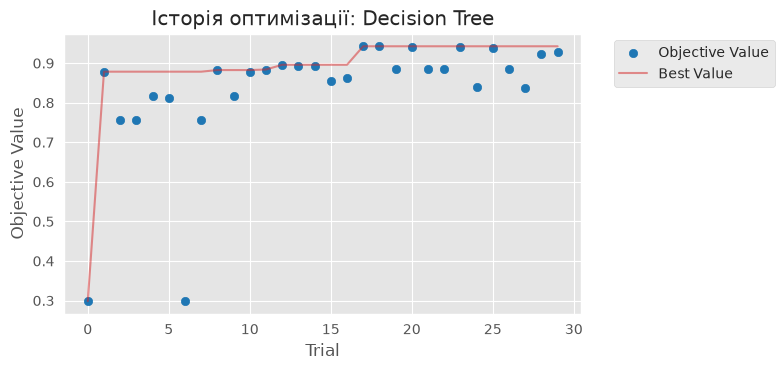

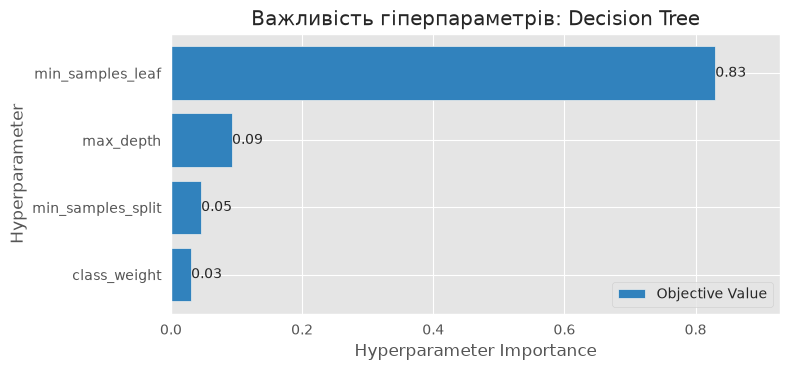

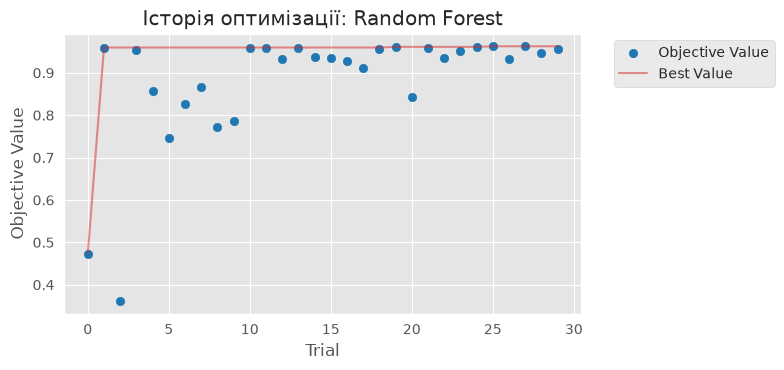

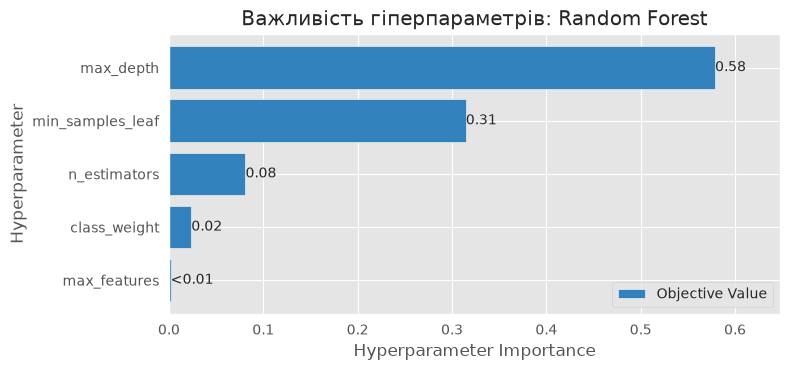

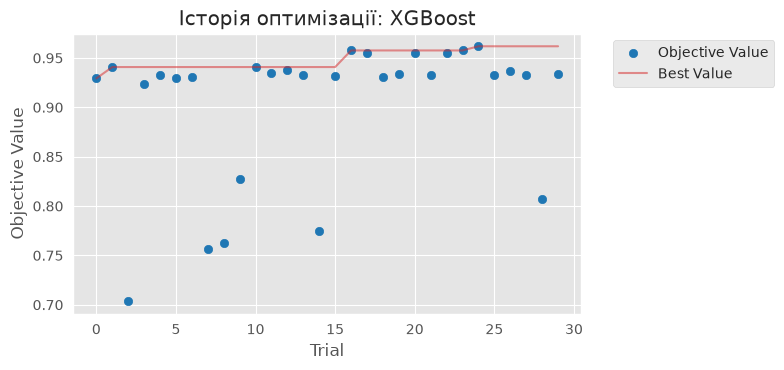

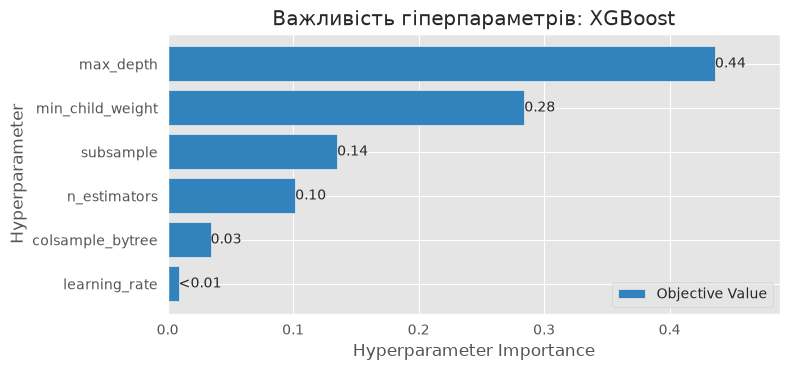

In [13]:
from optuna.visualization.matplotlib import plot_optimization_history, plot_param_importances
for name in MODELS:
    for plot_fn, title in [(plot_optimization_history, 'Історія оптимізації'),
                           (plot_param_importances, 'Важливість гіперпараметрів')]:
        ax = plot_fn(studies[name])
        ax.figure.set_size_inches(8, 3.8)
        for loc in ('left', 'center', 'right'):     # прибираємо рідний заголовок Optuna, щоб не накладався
            ax.set_title('', loc=loc)
        ax.set_title(f'{title}: {MODEL_FULL[name]}')
        plt.tight_layout(); plt.show()

**Опис результату (графік 3).** Для кожної моделі два графіки:
- **Історія оптимізації** (точки — оцінка кожної спроби, лінія — найкраща на цей момент). **DT:** спочатку ≈0.88, потім стрибок до ≈0.94 близько 17-ї спроби і далі плато: оптимізація збіглася. **RF:** уже на другій спробі ≈0.96 і далі майже не росте: багато налаштувань дають схожий результат, тобто RF мало чутливий до параметрів. **XGBoost:** майже плато ≈0.94 до 15-ї спроби, потім невеликі покращення до ≈0.962 (24-та спроба): оптимізація дала ще трохи.
- **Важливість гіперпараметрів.** **DT:** `min_samples_leaf` забирає ≈83% важливості. **RF:** `max_depth` (≈0.58) і `min_samples_leaf` (≈0.31). **XGBoost:** `max_depth` (≈0.44) і `min_child_weight` (≈0.28). Усе це параметри, що обмежують розмір листків та глибину, тобто **наскільки дерево може «виділити» крихітний клас 1**. Занадто великі мінімальні листки «вбивають» рідкісні класи й різко знижують macro F1 (це видно по найнижчих точках історії: оцінки 0.3–0.5 на кількох спробах).

### 4.3 Вкладена крос-валідація (чесна оцінка після підбору)

**Проблема.** Якщо підібрати параметри на train і одразу взяти `best_value` як якість моделі, оцінка буде **заниженою за помилкою (оптимістичною)**: параметри «підігнані» під ті самі блоки, на яких міряємо.

**Рішення: вкладена крос-валідація.** Зовнішній цикл ділить train на 5 блоків. Для кожного зовнішнього блоку:
1. `tune()` запускається **лише на його тренувальній частині** (внутрішня крос-валідація підбирає параметри);
2. модель з цими параметрами навчається на цій же частині;
3. якість міряється на зовнішньому валідаційному блоці, якого підбір **ніколи не бачив**.

Середнє по 5 блоках і є **неупереджена оцінка**. Вона відповідає на питання «яку якість дасть сама процедура підбору + навчання», а не якість однієї конкретної моделі. Цей етап найдовший (15 підборів), тому нижче друкується прогрес.

In [14]:
outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nested_scores = {n: [] for n in MODELS}
nested_inner_best = {n: [] for n in MODELS}      # best_value внутрішнього підбору на кожному блоці
nested_time = {}

for name in MODELS:
    t0 = time.time()
    for fold, (tr_idx, va_idx) in enumerate(outer.split(X_train, y_train), 1):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train[tr_idx]
        X_va, y_va = X_train.iloc[va_idx], y_train[va_idx]
        study = tune(name, X_tr, y_tr)
        model = build_pipeline(name, True, study.best_params).fit(X_tr, y_tr)
        nested_scores[name].append(f1_score(y_va, model.predict(X_va), average='macro'))
        nested_inner_best[name].append(study.best_value)
    nested_time[name] = time.time() - t0
    print(f'{MODEL_FULL[name]}: готово за {nested_time[name]:.0f} с; macro F1 по блоках = {np.round(nested_scores[name], 4)}')

Decision Tree: готово за 16 с; macro F1 по блоках = [0.9837 0.9922 0.8596 1.     0.9037]


Random Forest: готово за 436 с; macro F1 по блоках = [0.9767 1.     0.9161 1.     0.9809]


XGBoost: готово за 95 с; macro F1 по блоках = [0.9767 1.     0.9161 0.9864 0.9673]


**Опис результату.** Macro F1 на п'яти зовнішніх блоках:
- **DT:** 0.984, 0.992, 0.860, 1.000, 0.904 (≈16 с);
- **RF:** 0.977, 1.000, 0.916, 1.000, 0.981 (≈436 с — найдовше, бо 5 блоків × 30 спроб × великі ліси);
- **XGBoost:** 0.977, 1.000, 0.916, 0.986, 0.967 (≈95 с).

У різних блоках результат помітно коливається (наприклад, у третьому блоці всі моделі слабші, 0.86–0.92): це знову вплив того, що в блоці лишається один-два об'єкти класу 1.

In [15]:
t3 = pd.DataFrame({MODEL_FULL[n]: {
    'Вкладена CV, macro F1 (середнє ± std)': pm(nested_scores[n]),
    'study.best_value (звичайна оптимізація на всьому train)': round(studies[n].best_value, 4),
    'середнє best_value внутрішніх підборів': round(np.mean(nested_inner_best[n]), 4),
    'різниця: best_value − вкладена CV': round(studies[n].best_value - np.mean(nested_scores[n]), 4),
} for n in MODELS}).T
print('Таблиця 3. Вкладена крос-валідація, варіант B, після оптимізації')
display(t3)

Таблиця 3. Вкладена крос-валідація, варіант B, після оптимізації


,"Вкладена CV, macro F1 (середнє ± std)",study.best_value (звичайна оптимізація на всьому train),середнє best_value внутрішніх підборів,різниця: best_value − вкладена CV
Decision Tree,0.9478 ± 0.0627,0.9426,0.9492,-0.0052
Random Forest,0.9748 ± 0.0345,0.9627,0.9623,-0.0121
XGBoost,0.9693 ± 0.0321,0.9618,0.9505,-0.0075


**Опис результату (Таблиця 3).** Чесна оцінка (вкладена CV): **DT 0.948 ± 0.063, RF 0.975 ± 0.035, XGBoost 0.969 ± 0.032**. Для порівняння, `best_value` звичайної оптимізації на всьому train: 0.943, 0.963, 0.962. Різниця `best_value − вкладена CV` дорівнює **−0.005, −0.012, −0.008**.

**Це не те, чого очікують від «оптимістичної» оцінки**: ми чекали, що `best_value` вищий, а він трохи **нижчий**. Причини:
1. Різниця (≈0.005–0.012) набагато менша за розкид між блоками (σ ≈ 0.03–0.06), тобто в межах шуму.
2. Ці дві оцінки міряють трохи різне: у внутрішній 3-блочній CV модель навчається лише на 2/3 train (≈480 об'єктів, класу 1 лише ≈4), а в зовнішньому блоці модель навчається на 80% (≈575, клас 1 ≈4–5) і має кращу «статистику» для рідкісних класів. Це знижує `best_value` і компенсує оптимістичний зсув від вибору максимуму.

Практичний висновок: **теоретичний ризик оптимізму лишається** (best_value — це вибраний максимум), тому правильно подавати саме оцінку вкладеної CV; але на цих даних зсув виявився меншим за шум.

**Приріст після оптимізації** (вкладена CV, Таблиця 3, проти базової CV варіанта B, Таблиця 2; оцінки на різних розбиттях, тому порівняння орієнтовне):

| Модель | Типові параметри | Після Optuna | Зміна |
|---|---|---|---|
| Decision Tree | 0.969 | 0.948 | −0.021 |
| Random Forest | 0.964 | 0.975 | +0.011 |
| XGBoost | 0.945 | 0.969 | **+0.025** |

Найбільший приріст у **XGBoost** (типові параметри — глибокі дерева й швидке навчання — для малого датасету з рідкісними класами схильні до перенавчання, а Optuna знайшла обережніше налаштування). RF майже не змінився, а DT після підбору навіть не покращився: його типове налаштування (дерево без обмежень) і так було майже найкращим.

### 4.4 Фінальні моделі

Тепер навчаємо кожну модель із найкращими параметрами (Таблиця 4) на **всьому train**. Також навчаємо **базові моделі варіанта B** (типові параметри) на тому ж train, щоб потім порівняти «до» і «після» оптимізації на тесті. Тестову вибірку поки не чіпаємо.

In [16]:
final = {n: build_pipeline(n, True, studies[n].best_params).fit(X_train, y_train) for n in MODELS}
baseB = {n: build_pipeline(n, True).fit(X_train, y_train) for n in MODELS}
for n in MODELS:
    print(MODEL_FULL[n], 'навчено; ознак після обробки:', len(final[n].named_steps['prep'].get_feature_names_out()))

Decision Tree навчено; ознак після обробки: 77
Random Forest навчено; ознак після обробки: 77
XGBoost навчено; ознак після обробки: 77


## Етап 5. Статистичне порівняння (скоригований t-тест Надо–Бенжіо)

**Проблема.** Ми маємо 15 оцінок macro F1 для кожної моделі, і хочемо знати: чи різниця між двома моделями (або варіантами) **справжня, чи випадкова**. Звичайний парний t-тест тут не підходить: блоки крос-валідації **перетинаються за тренувальними даними**, тому оцінки між собою залежні, і звичайний t-тест занижує дисперсію та дає надто багато «значущих» різниць.

**Рішення.** Скоригований тест Надо–Бенжіо замінює множник дисперсії:

t = d̄ / √( (1/(k·r) + n_test/n_train) · σ̂²_d ), ступенів свободи k·r − 1,

де d_j — різниця метрик двох моделей на j-му блоці, d̄ та σ̂²_d — її середнє та вибіркова дисперсія, k=5 блоків, r=3 повторення, n_test/n_train = 1/4. Додатковий доданок n_test/n_train якраз враховує залежність блоків. Реалізуємо тест самі (кілька рядків) і порівнюємо з наївним парним t-тестом.

Перевіряємо при α = 0.05: (1) **A проти B** для кожної моделі; (2) **дві найкращі моделі** у варіанті B (за середнім macro F1 з Таблиці 2).

In [17]:
def nadeau_bengio(a, b, k=5, r=3):
    # скоригований t-тест Надо-Бенжіо для macro F1 з k x r крос-валідації
    d = np.asarray(a, float) - np.asarray(b, float)       # різниці на однакових блоках
    n = k * r
    ratio = (1 / k) / (1 - 1 / k)                         # n_test / n_train = 1/4
    var = d.var(ddof=1)
    if var == 0:
        t = 0.0 if d.mean() == 0 else np.sign(d.mean()) * np.inf
    else:
        t = d.mean() / np.sqrt((1 / n + ratio) * var)
    p = 2 * stats.t.sf(abs(t), df=n - 1) if np.isfinite(t) else 0.0
    return d.mean(), t, p

def f1s(variant, name): return base[(variant, name)]['test_f1m']

rows = []
for n in MODELS:
    dbar, t, p = nadeau_bengio(f1s('B', n), f1s('A', n))
    naive_p = stats.ttest_rel(f1s('B', n), f1s('A', n)).pvalue
    rows.append({'Порівняння': f'{MODEL_FULL[n]}: B проти A', 'd̄ (macro F1)': dbar, 't': t,
                 'p (Надо–Бенжіо)': p, 'p (наївний парний t)': naive_p,
                 'Висновок (α=0.05)': 'значуща' if p < 0.05 else 'незначуща'})

rank_B = sorted(MODELS, key=lambda n: np.mean(f1s('B', n)), reverse=True)
b1, b2 = rank_B[0], rank_B[1]
dbar, t, p = nadeau_bengio(f1s('B', b1), f1s('B', b2))
rows.append({'Порівняння': f'Найкращі в B: {MODEL_FULL[b1]} проти {MODEL_FULL[b2]}', 'd̄ (macro F1)': dbar, 't': t,
             'p (Надо–Бенжіо)': p, 'p (наївний парний t)': stats.ttest_rel(f1s('B', b1), f1s('B', b2)).pvalue,
             'Висновок (α=0.05)': 'значуща' if p < 0.05 else 'незначуща'})
print('Таблиця 5. Статистичне порівняння (скоригований t-тест Надо–Бенжіо, df = 14)')
t5 = pd.DataFrame(rows)
display(t5.round(4))
print('Рейтинг у варіанті B за середнім macro F1:', [(MODEL_FULL[n], round(np.mean(f1s('B', n)), 4)) for n in rank_B])

Таблиця 5. Статистичне порівняння (скоригований t-тест Надо–Бенжіо, df = 14)


,Порівняння,d̄ (macro F1),t,p (Надо–Бенжіо),p (наївний парний t),Висновок (α=0.05)
0,Decision Tree: B проти A,0.0773,2.2489,0.0411,0.0002,значуща
1,Random Forest: B проти A,0.0533,3.9013,0.0016,0.0000,значуща
2,XGBoost: B проти A,0.0565,1.0436,0.3144,0.0392,незначуща
3,Найкращі в B: Decision Tree проти Random Forest,0.0049,0.6951,0.4984,0.1521,незначуща


Рейтинг у варіанті B за середнім macro F1: [('Decision Tree', np.float64(0.9687)), ('Random Forest', np.float64(0.9638)), ('XGBoost', np.float64(0.9448))]


**Опис результату (Таблиця 5, скоригований тест Надо–Бенжіо, α = 0.05).**
- **A проти B:** DT: d̄ = +0.077, p = **0.041** → різниця значуща (на межі); RF: d̄ = +0.053, p = **0.0016** → значуща; XGBoost: d̄ = +0.057, p = **0.314** → **незначуща**.
- **Дві найкращі моделі у варіанті B (DT і RF):** d̄ = +0.005, p = **0.498** → різниця **незначуща**.

Як це розуміти:
- Індикатори пропусків **статистично значуще покращують** DT і RF. Для XGBoost середній приріст такого ж розміру (+0.057), але він «губиться» в розкиді (σ ≈ 0.07), тому довести його не вдалося.
- **Жодна з моделей у варіанті B не є статистично кращою за іншу:** DT, RF і XGBoost практично рівні за macro F1. Вибір між ними треба робити за іншими критеріями (стабільність, інтерпретовність, час).
- **Навіщо поправка.** Звичайний парний t-тест дав би набагато менші p (≈0.0002; <0.0001; 0.039; 0.15). Для XGBoost він хибно оголосив би різницю значущою (p = 0.039), бо не враховує, що блоки крос-валідації залежні. Скоригований тест правильно «охолоджує» цей результат.

## Етап 6. Фінальна оцінка на тестовій вибірці

Тепер **один раз** оцінюємо три фінальні моделі (варіант B, після оптимізації) на тестових даних, які раніше не використовувались (Таблиця 6). Для порівняння додаємо рядки «до оптимізації» (типові параметри). Далі для **найкращої моделі** друкуємо `classification_report` і будуємо матриці плутанини: абсолютну (скільки об'єктів) та нормалізовану по рядках (яка частка кожного справжнього класу куди потрапила).

Найкращу модель обираємо за **середнім macro F1 вкладеної крос-валідації** (а не за тестом), щоб тестова вибірка не впливала на вибір.

In [18]:
def test_scores(model):
    p = model.predict(X_test)
    return {'Accuracy': accuracy_score(y_test, p), 'Macro F1': f1_score(y_test, p, average='macro'),
            'Balanced Acc': balanced_accuracy_score(y_test, p)}

t6 = {}
for n in MODELS:
    t6[f'{MODEL_FULL[n]} (B, після Optuna)'] = test_scores(final[n])
for n in MODELS:
    t6[f'{MODEL_FULL[n]} (B, типові параметри)'] = test_scores(baseB[n])
t6 = pd.DataFrame(t6).T
print('Таблиця 6. Якість на тестовій вибірці (180 об\'єктів)')
display(t6.round(4))

best = max(MODELS, key=lambda n: np.mean(nested_scores[n]))
print('Найкраща модель за вкладеною CV:', MODEL_FULL[best])
pred_best = final[best].predict(X_test)
print(classification_report(y_test, pred_best, target_names=[f'клас {c}' for c in le.classes_], zero_division=0, digits=3))

Таблиця 6. Якість на тестовій вибірці (180 об'єктів)


,Accuracy,Macro F1,Balanced Acc
"Decision Tree (B, після Optuna)",0.9944,0.9285,0.9000
"Random Forest (B, після Optuna)",0.9944,0.9326,0.9000
"XGBoost (B, після Optuna)",0.9889,0.7986,0.8000
"Decision Tree (B, типові параметри)",0.9944,0.9285,0.9000
"Random Forest (B, типові параметри)",0.9944,0.9326,0.9000
"XGBoost (B, типові параметри)",0.9889,0.9270,0.8985


Найкраща модель за вкладеною CV: Random Forest


              precision    recall  f1-score   support

      клас 1      1.000     0.500     0.667         2
      клас 2      1.000     1.000     1.000        20
      клас 3      0.993     1.000     0.996       137
      клас 5      1.000     1.000     1.000        13
      клас U      1.000     1.000     1.000         8

    accuracy                          0.994       180
   macro avg      0.999     0.900     0.933       180
weighted avg      0.994     0.994     0.994       180



**Опис результату (Таблиця 6, 180 об'єктів у тесті).**

| Модель | Accuracy | Macro F1 | Balanced Acc |
|---|---|---|---|
| DT (B, після Optuna) | 0.994 | 0.929 | 0.900 |
| RF (B, після Optuna) | 0.994 | **0.933** | 0.900 |
| XGBoost (B, після Optuna) | 0.989 | **0.799** | 0.800 |
| DT (типові) | 0.994 | 0.929 | 0.900 |
| RF (типові) | 0.994 | 0.933 | 0.900 |
| XGBoost (типові) | 0.989 | 0.927 | 0.899 |

- **Accuracy ≈ 0.99 у всіх**: на тесті всього 1–2 помилки з 180. Це знову «ефект стелі».
- **Macro F1 після оптимізації в XGBoost упав до 0.799** (проти 0.927 до оптимізації). Це не означає, що оптимізація зіпсувала модель: у тесті **лише 2 об'єкти класу 1**, і налаштований XGBoost помилився на обох, через що F1 цього класу став 0, а macro F1 просіла приблизно на 0.13. Вкладена CV давала для цього ж XGBoost 0.969.
- Найкращою за вкладеною CV вибрано **Random Forest** (0.975). Його `classification_report`: класи 2, 3, 5 і U мають precision і recall ≈ 1.0; клас 1 має precision 1.0, але recall **0.5** (з двох об'єктів знайдено один), F1 = 0.667. Macro F1 = 0.933, accuracy = 0.994.

**Чому тест відрізняється від крос-валідації.** (1) Тест — це один розподіл із 180 об'єктів, а в ньому лише 2 об'єкти класу 1: кожен такий об'єкт «коштує» 0.07–0.13 macro F1. У CV ми усереднюємо 15 розбиттів. (2) Різниця в одну-дві помилки вже перевертає порядок моделей. Тому на цьому датасеті тестові числа треба читати разом із розкидом крос-валідації й тестами значущості, а не окремо.

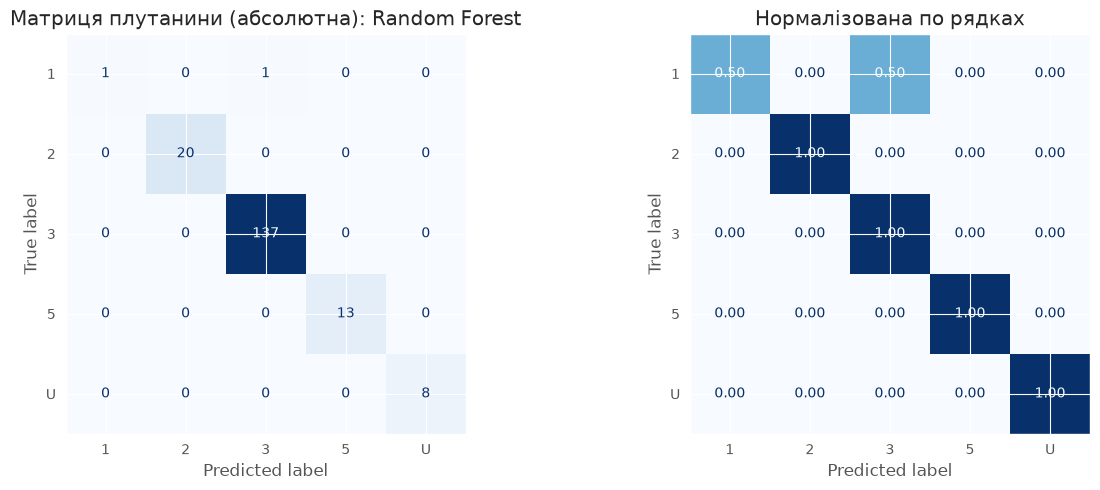

Помилки (справжній → прогноз, кількість): [('1', '3', 1)]
Усього помилок на тесті: 1 із 180


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test, pred_best, display_labels=le.classes_, ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title(f'Матриця плутанини (абсолютна): {MODEL_FULL[best]}')
ConfusionMatrixDisplay.from_predictions(y_test, pred_best, display_labels=le.classes_, normalize='true',
                                        values_format='.2f', ax=ax[1], cmap='Blues', colorbar=False)
ax[1].set_title('Нормалізована по рядках')
plt.tight_layout(); plt.show()

cm = pd.crosstab(pd.Series(le.inverse_transform(y_test), name='справжній'),
                 pd.Series(le.inverse_transform(pred_best), name='прогноз'))
off = [(r, c, int(cm.loc[r, c])) for r in cm.index for c in cm.columns if r != c and cm.loc[r, c] > 0]
off = sorted(off, key=lambda x: -x[2])
print('Помилки (справжній → прогноз, кількість):', off if off else 'помилок немає')
print('Усього помилок на тесті:', int((pred_best != y_test).sum()), 'із', len(y_test))

**Опис результату (графік 5, Random Forest).** Діагональ майже ідеальна: усі 20 об'єктів класу 2, усі 137 класу 3, усі 13 класу 5 і всі 8 класу U класифіковані правильно. **Єдина помилка: один із двох об'єктів класу 1 помилково віднесено до класу 3** (нормалізована матриця: клас 1 → 0.50 «клас 1» і 0.50 «клас 3»). Тобто найчастіше плутаються **клас 1 і клас 3**: клас 1 — найрідкісніший (8 об'єктів), а клас 3 — домінуючий (76%), тож модель при сумнівах обирає більшість.

## Етап 7. Інтерпретація: важливість ознак

Є два способи сказати, які ознаки важливі, і вони відповідають на різні питання.

**MDI** (*Mean Decrease in Impurity*, `feature_importances_`): скільки кожна ознака в сумі «зменшила неоднорідність» у вузлах дерев під час навчання. Рахується на **оброблених** ознаках (після one-hot та з індикаторами), тому категорія `family_GB` і індикатор `missingindicator_steel` бачимо окремо. Це швидко, але MDI **зміщена на користь ознак із багатьма унікальними значеннями** (по них дереву легше робити «зручні» розрізи), і рахується на train.

**Permutation importance:** перемішуємо значення однієї ознаки на **тестових** даних і дивимось, наскільки **падає macro F1**. Якщо падіння велике, модель на цю ознаку спиралась. Застосовуємо до **всього пайплайну на початкових ознаках**, робимо 10 повторень. Це чесніше, бо міряє вплив на реальний прогноз, але для корельованих ознак «ділить» важливість між ними.

Для кожної моделі будуємо графік top-15 обох видів (**графік 4**).

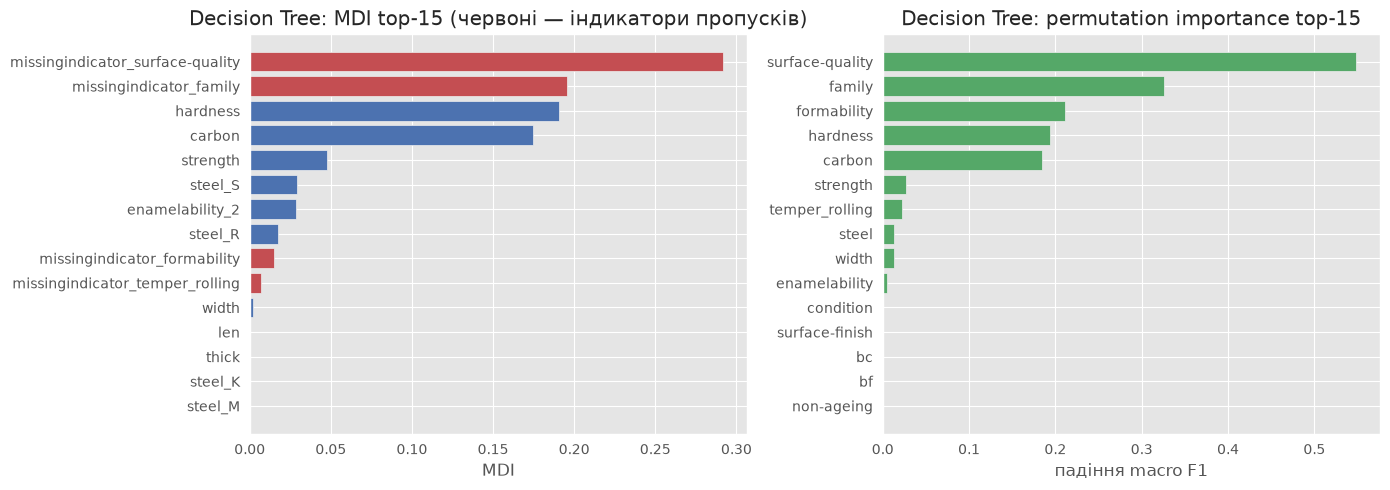

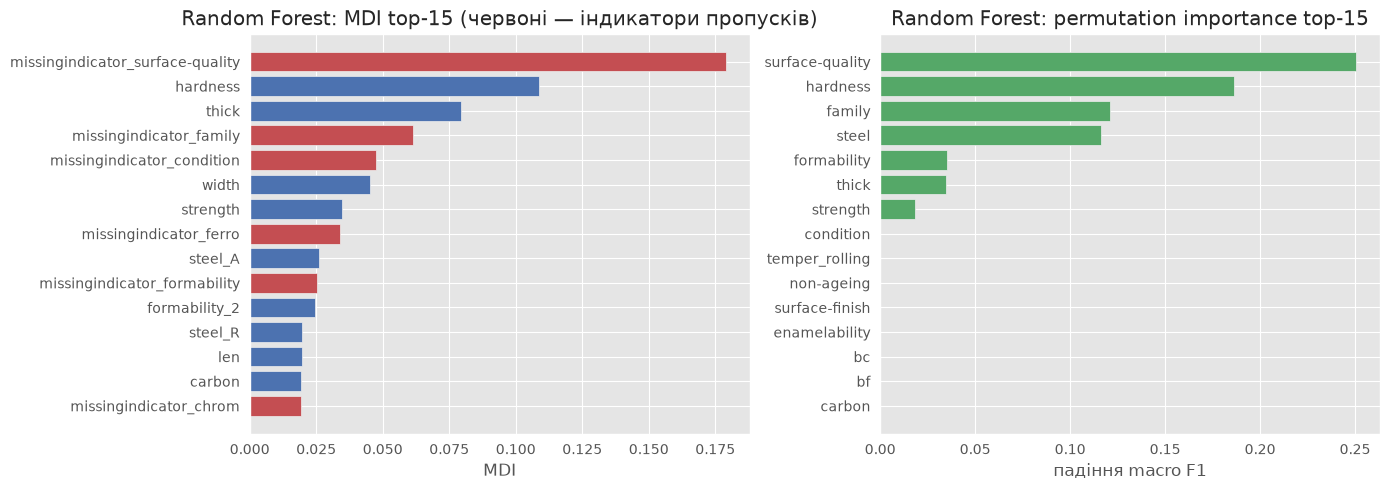

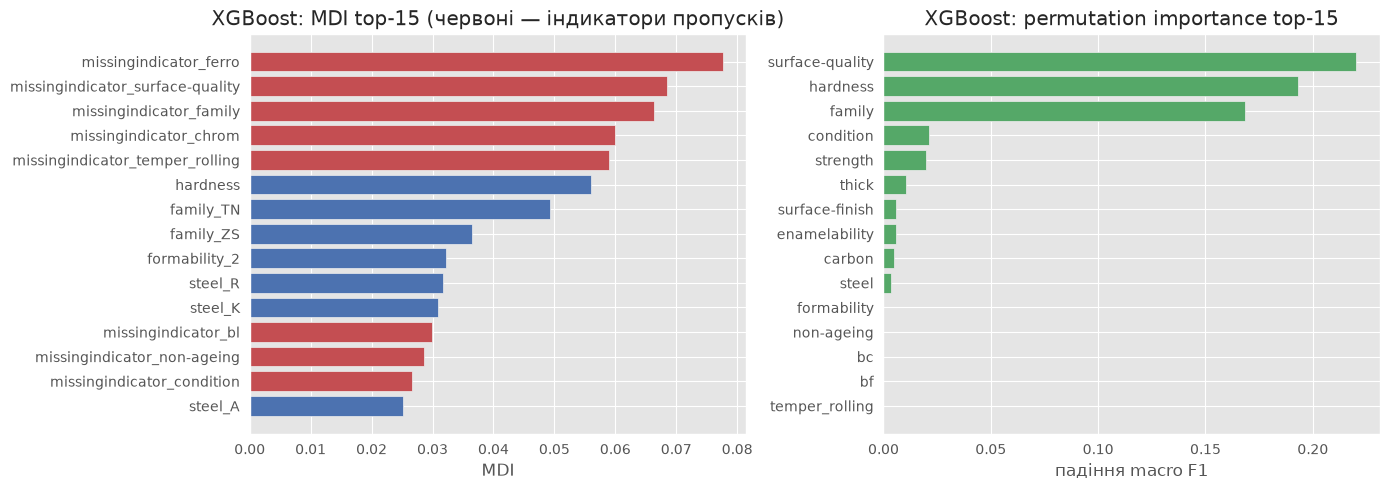

In [20]:
def clean(n):
    return n.replace('num__', '').replace('cat__', '').replace('miss__', '')

mdi, perm = {}, {}
for n in MODELS:
    prep = final[n].named_steps['prep']
    names = [clean(x) for x in prep.get_feature_names_out()]
    mdi[n] = pd.Series(final[n].named_steps['clf'].feature_importances_, index=names).sort_values(ascending=False)
    pi = permutation_importance(final[n], X_test, y_test, scoring='f1_macro', n_repeats=10,
                                random_state=SEED, n_jobs=1)
    perm[n] = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)

for n in MODELS:
    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    top = mdi[n].head(15)[::-1]
    ax[0].barh(top.index, top.values, color=['#C44E52' if 'missingindicator_' in i else '#4C72B0' for i in top.index])
    ax[0].set_title(f'{MODEL_FULL[n]}: MDI top-15 (червоні — індикатори пропусків)'); ax[0].set_xlabel('MDI')
    tp = perm[n].head(15)[::-1]
    ax[1].barh(tp.index, tp.values, color='#55A868')
    ax[1].set_title(f'{MODEL_FULL[n]}: permutation importance top-15'); ax[1].set_xlabel('падіння macro F1')
    plt.tight_layout(); plt.show()

**Опис результату (графік 4).** Для кожної моделі: ліворуч MDI (червоні стовпчики — індикатори пропусків), праворуч permutation importance (скільки втрачає macro F1 при перемішуванні ознаки на тесті).
- **Decision Tree.** MDI: на першому місці `missingindicator_surface-quality` (≈0.29), далі `missingindicator_family` (≈0.20), `hardness` (≈0.19), `carbon` (≈0.17). Permutation: `surface-quality` (падіння F1 ≈0.55), `family` (≈0.33), `formability` (≈0.21), `hardness`, `carbon`.
- **Random Forest.** MDI: `missingindicator_surface-quality` (≈0.18), `hardness` (≈0.11), `thick` (≈0.08), `missingindicator_family`. Permutation: `surface-quality` (≈0.25), `hardness` (≈0.19), `family` і `steel` (≈0.12).
- **XGBoost.** MDI: найвище індикатори `ferro`, `surface-quality`, `family`, `chrom`, `temper_rolling`. Permutation: `surface-quality` (≈0.22), `hardness` (≈0.19), `family` (≈0.17), далі значно менше.

In [21]:
# Чи потрапили індикатори пропусків у top-15 за MDI?
for n in MODELS:
    top15 = list(mdi[n].head(15).index)
    inds = [i for i in top15 if 'missingindicator_' in i]
    share_ind = mdi[n][[i for i in mdi[n].index if 'missingindicator_' in i]].sum()
    print(f'{MODEL_FULL[n]}: індикаторів у top-15 MDI = {len(inds)} {inds}; сумарна MDI всіх індикаторів = {share_ind:.3f}')

# Порівняння MDI і permutation: зводимо MDI до початкових ознак (one-hot і індикатор додаємо до своєї ознаки)
orig_cols = list(X_train.columns)
def to_orig(feat):
    f = feat.replace('missingindicator_', '')
    cands = [c for c in orig_cols if f == c or f.startswith(c + '_')]
    return max(cands, key=len) if cands else f
rows = []
for n in MODELS:
    agg = mdi[n].groupby(to_orig).sum().reindex(orig_cols).fillna(0)
    pr = perm[n].reindex(orig_cols).fillna(0)
    rho = stats.spearmanr(agg, pr).statistic
    top_m, top_p = list(agg.sort_values(ascending=False).index[:5]), list(pr.sort_values(ascending=False).index[:5])
    rows.append({'Модель': MODEL_FULL[n], 'Spearman(MDI, permutation)': round(rho, 3),
                 'top-5 за MDI': ', '.join(top_m), 'top-5 за permutation': ', '.join(top_p),
                 'спільних у top-5': len(set(top_m) & set(top_p))})
display(pd.DataFrame(rows))

Decision Tree: індикаторів у top-15 MDI = 4 ['missingindicator_surface-quality', 'missingindicator_family', 'missingindicator_formability', 'missingindicator_temper_rolling']; сумарна MDI всіх індикаторів = 0.509
Random Forest: індикаторів у top-15 MDI = 6 ['missingindicator_surface-quality', 'missingindicator_family', 'missingindicator_condition', 'missingindicator_ferro', 'missingindicator_formability', 'missingindicator_chrom']; сумарна MDI всіх індикаторів = 0.464
XGBoost: індикаторів у top-15 MDI = 8 ['missingindicator_ferro', 'missingindicator_surface-quality', 'missingindicator_family', 'missingindicator_chrom', 'missingindicator_temper_rolling', 'missingindicator_bl', 'missingindicator_non-ageing', 'missingindicator_condition']; сумарна MDI всіх індикаторів = 0.511


,Модель,"Spearman(MDI, permutation)",top-5 за MDI,top-5 за permutation,спільних у top-5
0,Decision Tree,0.987,"surface-quality, family, hardness, carbon, str...","surface-quality, family, formability, hardness...",4
1,Random Forest,0.718,"surface-quality, hardness, family, steel, thick","surface-quality, hardness, family, steel, form...",4
2,XGBoost,0.555,"family, steel, surface-quality, ferro, formabi...","surface-quality, hardness, family, condition, ...",2


**Опис результату.**

*Чи є індикатори пропусків у top-15 за MDI?* **Так, у всіх трьох моделей:** DT — 4 індикатори (з них `surface-quality`, `family`), RF — 6, XGBoost — 8. Сумарна MDI усіх індикаторів ≈0.51 (DT), ≈0.46 (RF), ≈0.51 (XGB): тобто приблизно половина «вагомості» моделей припадає на факт пропуску. Це **узгоджується з аналізом механізму пропусків**: пропуск залежить від класу (Cramér's V для `surface-quality` 0.74, `family` 0.72), тож моделі справді використовують його як ознаку класу, і саме тому варіант B виграв.

*Наскільки узгоджуються MDI та permutation?* Кореляція Спірмена (після зведення MDI до початкових ознак): DT **0.99**, RF **0.72**, XGBoost **0.56**; спільних ознак у top-5: 4, 4 і 2. Для одного дерева методи майже збігаються, а для ансамблів розходяться сильніше. Приклади розбіжності:
- У XGBoost індикатори `ferro` і `chrom` мають найвищу MDI, але при перемішуванні майже не змінюють F1: вони **дублюють** інформацію інших індикаторів (`surface-quality`, `family`), тож модель не страждає без одного з них. MDI «ділить» важливість між корельованими ознаками й завищує її.
- У RF неперервні `thick` і `width` мають високу MDI (≈0.08 і ≈0.045), а permutation показує, що перемішування `thick` коштує лише ≈0.035, а `width` ≈0: це приклад **зміщення MDI на користь ознак із багатьма унікальними значеннями** (по них дереву просто легше робити «зручні» розрізи на train).

*Чому важливості однієї ознаки відрізняються між DT, RF і XGBoost?* Одне дерево жорстко вибирає кілька «найкращих» розрізів і ігнорує решту, тому в нього важливість зосереджена на 4–5 ознаках. RF у кожному вузлі розглядає випадкову підмножину ознак, тому ділить внесок між кількома схожими ознаками. XGBoost будує дерева послідовно, кожне виправляє помилки попередніх, тож залучає багато ознак, у тому числі «дублери».

## Етап 8. Аналіз розбіжностей між моделями

**Об'єкт розбіжності** — це об'єкт, де прогнози трьох фінальних моделей **не всі однакові** (достатньо, щоб відрізнялась хоча б одна). Шукаємо такі об'єкти на тесті. Якщо їх менше трьох (на цьому датасеті через «ефект стелі» це можливо), додаємо об'єкти з train, використовуючи **out-of-fold прогнози** (`cross_val_predict`): кожен об'єкт прогнозується моделлю, яка його **не бачила** під час навчання. Прогнози моделей на їхніх же тренувальних даних для цього брати не можна: вони майже завжди ідеальні.

Результат — **Таблиця 7** у форматі зразка з завдання. Для одного об'єкта потім робимо детальний розбір (значення ознак, що було пропущено й чим заповнено, SHAP-внески).

In [22]:
preds_test = {n: final[n].predict(X_test) for n in MODELS}
P = np.vstack([preds_test[n] for n in MODELS])
dis_mask = ~(P == P[0]).all(axis=0)
print('Об\'єктів розбіжності на тесті:', int(dis_mask.sum()), 'із', len(y_test))

rows = []
for i in np.where(dis_mask)[0]:
    rows.append({'Об\'єкт': f'#{X_test.index[i]}', 'Джерело': 'test',
                 'Справжній клас': le.classes_[y_test[i]],
                 **{MODEL_FULL[n]: le.classes_[preds_test[n][i]] for n in MODELS}})

n_need = max(0, 3 - len(rows))
oof_rows = []
if n_need > 0:
    print(f'На тесті менше трьох: додаємо об\'єкти з train за out-of-fold прогнозами')
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
    oof = {n: cross_val_predict(clone(final[n]), X_train, y_train, cv=skf) for n in MODELS}
    Po = np.vstack([oof[n] for n in MODELS])
    dis_tr = np.where(~(Po == Po[0]).all(axis=0))[0]
    print('Об\'єктів розбіжності у train (OOF):', len(dis_tr))
    for i in dis_tr[:max(n_need, 3)]:
        oof_rows.append({'Об\'єкт': f'#{X_train.index[i]}', 'Джерело': 'train (OOF)',
                         'Справжній клас': le.classes_[y_train[i]],
                         **{MODEL_FULL[n]: le.classes_[oof[n][i]] for n in MODELS}})
t7 = pd.DataFrame(rows + oof_rows)
print('Таблиця 7. Об\'єкти розбіжності між прогнозами моделей')
display(t7)

Об'єктів розбіжності на тесті: 2 із 180
На тесті менше трьох: додаємо об'єкти з train за out-of-fold прогнозами


Об'єктів розбіжності у train (OOF): 9
Таблиця 7. Об'єкти розбіжності між прогнозами моделей


,Об'єкт,Джерело,Справжній клас,Decision Tree,Random Forest,XGBoost
0,#24,test,1,2,3,3
1,#188,test,1,1,1,3
2,#453,train (OOF),U,3,U,U
3,#720,train (OOF),U,U,3,U
4,#90,train (OOF),U,U,3,3


**Опис результату (Таблиця 7).** На тесті **лише 2 об'єкти розбіжності** з 180 (ефект стелі), тому додано 3 об'єкти з train за out-of-fold прогнозами (моделі їх не бачили під час навчання; це явно позначено в колонці «Джерело»).
- **#24 (клас 1):** DT → 2, RF → 3, XGBoost → 3; **усі три помилилися**.
- **#188 (клас 1):** DT і RF вгадали (1), XGBoost → 3 (саме через це тестовий macro F1 у XGBoost така низька).
- **#453 (клас U):** DT → 3, RF і XGBoost → U.
- **#720 (клас U):** RF → 3, DT і XGBoost → U.
- **#90 (клас U):** DT → U, RF і XGBoost → 3.

Усі п'ять розбіжностей стосуються **рідкісних класів (1 та U)**: на великих класах (3, 2, 5) моделі погоджуються.

### 8.1 Детальний аналіз одного об'єкта розбіжності

Беремо один об'єкт (перевага — об'єкту з тесту, бо його моделі точно не бачили). Показуємо:
1. усі ознаки з **початковими** значеннями; ті, що були пропущені, позначені, разом із **значенням, яким їх заповнив імпутер** (медіана або мода, обчислені на train);
2. **ймовірності класів** (`predict_proba`) від кожної моделі: видно, наскільки впевнена кожна;
3. **SHAP-значення** (`shap.TreeExplainer`): внесок кожної ознаки в прогноз. Додатний внесок «штовхає» до прогнозованого класу, від'ємний — відштовхує. Показуємо 5 ознак із найбільшим за модулем внеском для **прогнозованого моделлю класу** (**графік 6**).

In [23]:
# Вибір об'єкта: спершу з тесту
if dis_mask.any():
    pos = int(np.where(dis_mask)[0][0]); row = X_test.iloc[[pos]]; true_cls = le.classes_[y_test[pos]]; src = 'test'
else:
    i0 = int(dis_tr[0]); row = X_train.iloc[[i0]]; true_cls = le.classes_[y_train[i0]]; src = 'train (OOF)'
print(f'Об\'єкт #{row.index[0]} (джерело: {src}), справжній клас: {true_cls}')

prep = final['DT'].named_steps['prep']          # імпутери однакові для всіх трьох моделей (fit на тому ж train)
num_cols = list(prep.transformers_[0][2]); cat_cols_ = list(prep.transformers_[1][2])
num_fill = dict(zip(num_cols, prep.named_transformers_['num'].statistics_))
cat_fill = dict(zip(cat_cols_, prep.named_transformers_['cat'].named_steps['impute'].statistics_))
fill = {**num_fill, **cat_fill}

det = pd.DataFrame({'значення (до імпутації)': row.iloc[0].values}, index=row.columns)
det['пропущено?'] = row.iloc[0].isna().map({True: 'ПРОПУЩЕНО', False: ''}).values
det['чим заповнено'] = [fill[c] if row[c].isna().iloc[0] else '' for c in row.columns]
print('Ознаки об\'єкта:', len(det), '| пропущених:', int(row.iloc[0].isna().sum()))
display(det[det['пропущено?'] != ''])                  # пропущені та чим заповнені
display(det[det['пропущено?'] == ''][['значення (до імпутації)']].T)   # решта (непропущені)

proba = pd.DataFrame({MODEL_FULL[n]: final[n].predict_proba(row)[0] for n in MODELS}, index=[f'клас {c}' for c in le.classes_]).T
proba['прогноз'] = [le.classes_[final[n].predict(row)[0]] for n in MODELS]
print('Ймовірності класів за моделями:')
display(proba.round(3))

Об'єкт #24 (джерело: test), справжній клас: 1
Ознаки об'єкта: 31 | пропущених: 20


,значення (до імпутації),пропущено?,чим заповнено
family,NaN,ПРОПУЩЕНО,TN
condition,NaN,ПРОПУЩЕНО,S
formability,NaN,ПРОПУЩЕНО,2
non-ageing,NaN,ПРОПУЩЕНО,N
surface-finish,NaN,ПРОПУЩЕНО,P
surface-quality,NaN,ПРОПУЩЕНО,E
enamelability,NaN,ПРОПУЩЕНО,2
bc,NaN,ПРОПУЩЕНО,Y
bt,NaN,ПРОПУЩЕНО,Y
bw/me,NaN,ПРОПУЩЕНО,B


,steel,carbon,hardness,temper_rolling,strength,bf,shape,thick,width,len,bore
значення (до імпутації),A,3.0,0.0,T,0.0,Y,COIL,0.5,610.0,0.0,0


Ймовірності класів за моделями:


,клас 1,клас 2,клас 3,клас 5,клас U,прогноз
Decision Tree,0.000,1.000,0.000,0.000,0.000,2
Random Forest,0.050,0.065,0.820,0.040,0.025,3
XGBoost,0.012,0.034,0.908,0.016,0.030,3


**Опис результату (детальний розбір об'єкта #24 з тесту, справжній клас 1).**
- З 31 ознаки **20 були пропущені**: усі, крім 11 (`steel=A`, `carbon=3`, `hardness=0`, `temper_rolling=T`, `strength=0`, `bf=Y`, `shape=COIL`, `thick=0.5`, `width=610`, `len=0`, `bore=0`). У першій таблиці показано пропущені ознаки та значення, якими їх заповнив імпутер (мода: наприклад, `family=TN`, `condition=S`, `surface-quality=E`, `formability=2`). Ці значення — **найчастіші по train**, тобто для цього об'єкта вони, найімовірніше, вигадані, а правда в тому, що вони «не застосовні».
- **Ймовірності (таблиця):** DT — клас 2 з ймовірністю **1.000** (одне дерево, один листок, жодних сумнівів); RF — клас 3 з 0.82 (клас 1 лише 0.05); XGBoost — клас 3 з 0.91 (клас 1 лише 0.01). Усі три помилилися, а **справжньому класу 1 віддали майже нульову ймовірність**.

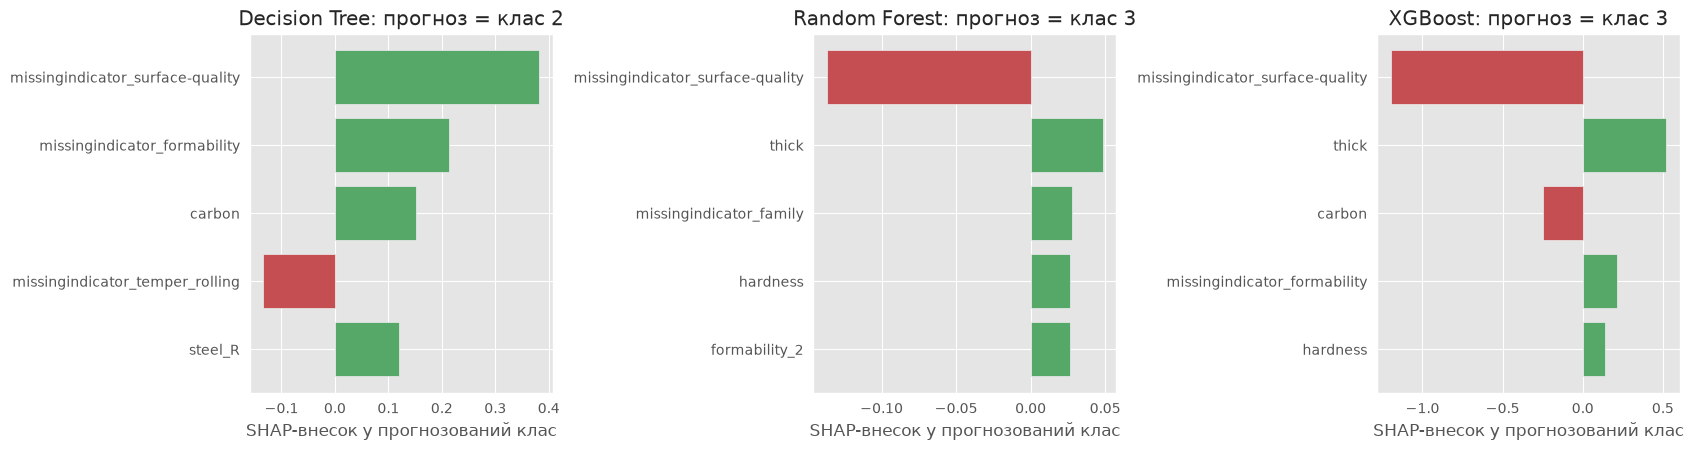

,Модель,Прогноз,Ознака,SHAP
0,Decision Tree,2,missingindicator_surface-quality,0.3817
1,Decision Tree,2,missingindicator_formability,0.2141
2,Decision Tree,2,carbon,0.1516
3,Decision Tree,2,missingindicator_temper_rolling,-0.1337
4,Decision Tree,2,steel_R,0.1191
5,Random Forest,3,missingindicator_surface-quality,-0.1365
6,Random Forest,3,thick,0.0483
7,Random Forest,3,missingindicator_family,0.0277
8,Random Forest,3,hardness,0.0267
9,Random Forest,3,formability_2,0.0263


In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
shap_rows = []
for ax, n in zip(axes, MODELS):
    pipe = final[n]
    Xt = pipe.named_steps['prep'].transform(row)
    names = [clean(x) for x in pipe.named_steps['prep'].get_feature_names_out()]
    explainer = shap.TreeExplainer(pipe.named_steps['clf'])
    sv = explainer.shap_values(Xt)
    if isinstance(sv, list):                                  # старий формат shap: список по класах
        sv = np.stack(sv, axis=-1)
    sv = np.asarray(sv)                                       # форма (n_samples, n_features, n_classes)
    pc = int(pipe.predict(row)[0])
    contrib = pd.Series(sv[0, :, pc], index=names)
    top5 = contrib.reindex(contrib.abs().sort_values(ascending=False).index).head(5)
    for f, v in top5.items():
        shap_rows.append({'Модель': MODEL_FULL[n], 'Прогноз': le.classes_[pc], 'Ознака': f, 'SHAP': round(v, 4)})
    ax.barh(top5.index[::-1], top5.values[::-1], color=['#C44E52' if v < 0 else '#55A868' for v in top5.values[::-1]])
    ax.set_title(f'{MODEL_FULL[n]}: прогноз = клас {le.classes_[pc]}'); ax.set_xlabel('SHAP-внесок у прогнозований клас')
plt.tight_layout(); plt.show()
display(pd.DataFrame(shap_rows))

**Опис результату (графік 6, п'ять найбільших SHAP-внесків у прогнозований клас).**
- **Decision Tree (прогноз: клас 2).** Найбільше «за» клас 2 дає `missingindicator_surface-quality` (+0.38), далі `missingindicator_formability` (+0.21), `carbon` (+0.15) і `steel_R` (+0.12); проти — `missingindicator_temper_rolling` (−0.13). Пропуск `surface-quality` в навчальних даних дуже типовий для класу 2 (89 з 99), тож одне дерево жорстко «відсікає» об'єкт у клас 2.
- **Random Forest (прогноз: клас 3).** Тут головний внесок **від'ємний**: `missingindicator_surface-quality` дає −0.14 (пропуск проти класу 3). Але кілька дрібних «за»: `thick` (+0.05), `missingindicator_family`, `hardness`, `formability_2` (≈+0.03 кожен). Клас 3 вигравав, бо ліс **усереднює сотні дерев**, і більшість голосує за домінуючий клас.
- **XGBoost (прогноз: клас 3).** Знову найбільший внесок у `missingindicator_surface-quality`, але **−1.20** (сильно проти класу 3), а за клас 3: `thick` (+0.52), `missingindicator_formability` (+0.21), `hardness` (+0.14); проти: `carbon` (−0.25). Шкала в XGBoost інша (SHAP у log-odds, ±1), у RF це ймовірності (±0.1), тому числа між моделями порівнювати можна лише за знаком і порядком.

**Чому моделі розійшлися.** (1) У об'єкта 20 з 31 ознаки пропущені, тому рішення в основному тримається на **індикаторах і значеннях-«заповнювачах»**, які для одного дерева є жорсткими порогами, а в ансамблях усереднюються. (2) Дерево розганяє малозначну різницю в величезну впевненість (1.000), тоді як RF/XGBoost «розмазують» голоси. (3) Об'єкт лежить на **межі класів 1, 2, 3** (класу 1 всього 8 прикладів): жодна модель не віддала йому >0.05 ймовірності, тож це радше складний випадок, ніж помилка однієї моделі.

## Збереження версій бібліотек (requirements.txt)

За вимогою звіту фіксуємо версії бібліотек, з якими виконано роботу, у файл `requirements.txt`.

In [25]:
from importlib.metadata import version
pkgs = ['numpy', 'pandas', 'scipy', 'scikit-learn', 'xgboost', 'optuna', 'shap', 'matplotlib', 'seaborn']
req = '\n'.join(f'{p}=={version(p)}' for p in pkgs)
open('requirements.txt', 'w').write(req + '\n')
print(req)

numpy==2.2.6
pandas==2.3.3
scipy==1.16.2
scikit-learn==1.8.0
xgboost==3.4.1
optuna==5.0.0
shap==0.53.0
matplotlib==3.11.2
seaborn==0.13.2


**Опис результату.** Файл `requirements.txt` збережено поруч із ноутбуком (його також надіслано окремо). Потрібні пакети встановлюються командою `pip install -r requirements.txt`.

## Висновок

**1.** За **macro F1** у варіанті B (типові параметри) DT, RF і XGBoost майже рівні (0.969 ± 0.055, 0.964 ± 0.052, 0.945 ± 0.068), а після підбору Optuna (вкладена CV) найкращий **Random Forest** (0.975 ± 0.035), далі XGBoost (0.969 ± 0.032) і Decision Tree (0.948 ± 0.063); результат нестабільний (σ ≈ 0.03–0.06 через рідкісні класи), і **перевага однієї моделі над іншою статистично не доведена** (DT проти RF: p = 0.50). **2.** Індикатори пропусків підняли macro F1 на 0.05–0.08 (значуще для DT, p = 0.041, і RF, p = 0.0016, але не для XGBoost, p = 0.31), що узгоджується з аналізом механізму: у 20 із 23 ознак пропуск пов'язаний із класом (Cramér's V до 0.74), тобто це не MCAR, а структурні пропуски, і індикатори пропусків потрапляють у top-15 за MDI в усіх моделей (4, 6 і 8 штук), а `missingindicator_surface-quality` посідає перше місце. **3.** Оцінка вкладеної CV (0.948, 0.975, 0.969) відрізнялась від `best_value` (0.943, 0.963, 0.962) лише на 0.005–0.012 і навіть була вищою, тобто оптимістичного зсуву в межах шуму не видно, проте `best_value` лишається вибраним максимумом і правильно звітувати саме вкладену CV. **4.** Найбільший приріст після оптимізації отримав XGBoost (+0.025), тому що його типові глибокі дерева й швидке навчання перенавчаються на малих класах, а Optuna знайшла обережніші параметри (глибина 3, швидкість 0.016); DT не покращився. **5.** Найскладніший клас **1** (лише 8 об'єктів, 2 у тесті): його плутають із домінуючим класом 3 (recall на тесті 0.5), тоді як класи 2, 3, 5 і U класифікуються майже ідеально. **6.** Аналіз розбіжностей показав, що моделі сперечаються лише на рідкісних класах (1 та U); для об'єкта #24 усі три моделі помилились, DT був упевнений на 100% (клас 2), а RF і XGBoost віддали 0.82–0.91 класу 3, і в SHAP домінує індикатор пропуску `surface-quality`. **7.** Для практики доцільно обрати **Random Forest** (найкраща вкладена CV, accuracy 0.994 і macro F1 0.933 на тесті, стабільніший за одне дерево, у ~3 рази повільніше підбирається, ніж XGBoost, але навчається за долі секунди), а коли потрібна максимальна простота й інтерпретовність, достатньо Decision Tree з індикаторами пропусків, бо статистично він не гірший.

## Відповіді на контрольні питання

**1. Чим випадковий ліс відрізняється від одного дерева з погляду зсуву та дисперсії? Яку роль відіграє декореляція дерев?**
Одне глибоке дерево має малий зсув (воно підлаштовується під дані), але **велику дисперсію**: невелика зміна навчальних даних дає зовсім інше дерево. Випадковий ліс усереднює багато дерев, навчених на різних бутстреп-вибірках, і тим **знижує дисперсію**, майже не збільшуючи зсув. Але усереднення зменшує дисперсію лише тоді, коли дерева **різні, не корельовані** між собою (середнє n однакових дерев дисперсії не зменшує). Тому в кожному вузлі розглядають лише випадкову підмножину ознак (`max_features`): це **декорелює** дерева.

**2. Різниця між бустингом і беггінгом? Який схильніший до перенавчання зі збільшенням кількості дерев?**
**Беггінг** (RF) навчає дерева **паралельно й незалежно** на різних вибірках і усереднює їх (знижує дисперсію). **Бустинг** (XGBoost) будує дерева **послідовно**: кожне нове виправляє помилки попередніх (знижує зсув). У RF додавання дерев перенавчання не збільшує (точність виходить на плато). У бустингу з ростом кількості дерев модель продовжує підлаштовуватися під тренувальні дані (в тому числі під шум), тож він **схильніший до перенавчання**; це стримують малою швидкістю навчання, обмеженою глибиною та регуляризацією (`learning_rate`, `max_depth`, `min_child_weight`, `subsample`).

**3. Чому macro F1 і balanced accuracy інформативніші за accuracy при дисбалансі? Різниця між macro- і weighted-усередненням F1?**
Accuracy рахує частку правильних відповідей, тому велика більшість (тут клас 3 — 76%) «тягне» її вгору, навіть якщо рідкісні класи не розпізнаються взагалі. Macro F1 і balanced accuracy рахують якість **окремо для кожного класу** й усереднюють, тому помилки на малих класах помітні. **Macro**-усереднення дає всім класам однакову вагу; **weighted** зважує F1 кожного класу за його розміром, тому знову домінує великий клас і weighted F1 мало відрізняється від accuracy (у нашому звіті: weighted 0.994 проти macro 0.933).

**4. Механізми MCAR, MAR, MNAR. За якого механізму індикатори найкорисніші? Чи можна за даними відрізнити MAR від MNAR?**
**MCAR** — ймовірність пропуску не залежить ні від спостережуваних, ні від непомічених даних (чиста випадковість). **MAR** — залежить лише від спостережуваних ознак (у нас: від класу чи інших ознак). **MNAR** — залежить від самого пропущеного значення чи від неспостережуваних чинників. Індикатори найкорисніші при **MAR/MNAR** та **структурних** пропусках, бо тоді факт пропуску несе інформацію про ціль (у нас так і є). При MCAR індикатор лише додає шум. **Однозначно відрізнити MAR від MNAR за самими даними не можна**: для цього треба знати значення, яких немає, тому потрібні додаткові знання про процес збору даних.

**5. Де в пайплайні може бути витік даних під час імпутації та оптимізації? Як запобігти?**
Витік виникає, коли імпутер, кодувальник чи інше перетворення «навчається» на всьому датасеті до розбиття або на валідаційних блоках (медіана рахується з урахуванням тесту), і коли в Optuna передають вже оброблені дані чи використовують тест у цільовій функції. Запобігання: **усі кроки обробки всередині `Pipeline`** (тоді при крос-валідації вони навчаються лише на тренувальній частині блоку); у цільову функцію Optuna передавати **весь пайплайн**; тест чіпати **лише один раз** в кінці.

**6. Чому `best_value` — оптимістично зміщена оцінка? Як працює вкладена CV і що вона оцінює?**
Optuna пробує багато комбінацій і повертає **максимум** серед зашумлених оцінок; максимум випадкових величин систематично більший за їхнє середнє, а параметри підібрано саме під ці блоки. Вкладена CV: у **внутрішньому** циклі на тренувальній частині зовнішнього блоку підбираються параметри, а в **зовнішньому** модель оцінюється на блоці, якого підбір не бачив. Вона оцінює **якість всієї процедури** «підбір параметрів + навчання», а не якість однієї конкретної фінальної моделі.

**7. Чому звичайний парний t-тест не підходить для порівняння результатів CV? Яку поправку вносить тест Надо–Бенжіо?**
Тренувальні частини блоків сильно перетинаються (одні й ті самі об'єкти потрапляють у різні блоки), тому оцінки на блоках **залежні**, а парний t-тест вважає їх незалежними й **занижує дисперсію**, давши надто багато хибних «значущих» різниць. Тест Надо–Бенжіо замінює множник 1/(k·r) на **1/(k·r) + n_test/n_train**, збільшуючи оцінку дисперсії: це враховує залежність блоків. У нашій роботі саме для XGBoost наївний тест дав p = 0.039 (значуща), а скоригований p = 0.31 (незначуща).

**8. Чим MDI відрізняється від permutation importance? Як корельовані ознаки впливають на кожну?**
**MDI** — внутрішня міра дерев (скільки ознака зменшила неоднорідність у вузлах), рахується на train по оброблених ознаках; вона зміщена на користь ознак із багатьма унікальними значеннями. **Permutation importance** — падіння якості при перемішуванні ознаки на тестових даних, рахується для будь-якої моделі й міряє реальний вплив на прогноз. Для **корельованих ознак**: MDI розподіляє важливість між ними довільно (одну «обирає» дерево); permutation може показати обидві ознаки як малі, бо модель компенсує перемішану ознаку її «дублером» (як індикатори `ferro` і `chrom` в XGBoost).

**9. Що таке SHAP-значення і яку властивість (адитивність) вони задовольняють? Локальне пояснення проти глобальної важливості?**
SHAP-значення (з теорії ігор, значення Шеплі) показують внесок кожної ознаки в конкретний прогноз порівняно з «середнім» прогнозом. Властивість **адитивності**: сума SHAP-значень усіх ознак плюс базовий (середній) прогноз точно дорівнює прогнозу моделі для цього об'єкта. **Локальне** пояснення відповідає на питання «чому саме цей об'єкт отримав такий клас» (як наш графік 6), **глобальна** важливість (MDI, permutation) — «які ознаки важливі для моделі загалом». Усереднивши модулі SHAP по багатьох об'єктах, можна отримати й глобальну важливість.

**10. Як XGBoost обробляє пропущені значення нативно (sparsity-aware split finding)?**
Для кожного розрізу XGBoost пробує відправити об'єкти з пропуском в обидві гілки (ліву або праву) і обирає напрямок, що дає більше зменшення втрат; цей **напрямок за замовчуванням** запам'ятовується для кожного вузла. Тож модель сама вчиться, куди «класти» пропуски, і працює лише з непропущеними значеннями при пошуку порогу (це ще й пришвидшує обробку розріджених даних). У цій роботі імпутацію застосовано навмисно, щоб усі моделі отримували однакові вхідні дані.

**11. Які переваги має Optuna (TPE, прунінг) порівняно з GridSearchCV та RandomizedSearchCV?**
GridSearchCV перебирає всі комбінації (кількість зростає експоненційно), а RandomizedSearchCV пробує випадкові, не вчачись на попередніх спробах. **TPE** в Optuna будує модель того, які області простору дають хороші результати, і наступні спроби робить саме там, тому знаходить хороші параметри за значно меншу кількість спроб. **Прунінг** передчасно зупиняє безперспективні спроби (відсікає ті, що вже на початку гірші), заощаджуючи час. Optuna також зручно працює з умовними й логарифмічними просторами (як `learning_rate` від 0.01 до 0.3 в логарифмічній шкалі) і має візуалізації історії та важливості параметрів.